In [88]:
import pandas as pd
import numpy as np

dial = pd.read_csv(
    "../data/dial_attempts_with_target.csv"
)

phones = pd.read_csv(
    "../data/phone_contacts.csv"
)

accounts = pd.read_csv(
    "../data/accounts.csv"
)

splits = pd.read_csv(
    "../data/splits.csv"
)

print("Dial:", dial.shape)
print("Phones:", phones.shape)
print("Accounts:", accounts.shape)
print("Splits:", splits.shape)

Dial: (51061, 17)
Phones: (5719, 7)
Accounts: (2400, 20)
Splits: (2400, 2)


In [2]:
dial["attempt_ts"] = pd.to_datetime(
    dial["attempt_ts"]
)

dial = dial.sort_values(
    ["account_id", "phone_id", "attempt_ts"]
).reset_index(drop=True)

dial[[
    "account_id",
    "phone_id",
    "attempt_ts",
    "disposition",
    "is_rpc"
]].head(20)

,account_id,phone_id,attempt_ts,disposition,is_rpc
0,AC000001,PH000611,2026-04-04 09:14:39,switched_off,0
1,AC000001,PH000611,2026-04-04 14:57:03,not_reachable,0
2,AC000001,PH000611,2026-04-07 12:38:03,not_reachable,0
3,AC000001,PH000611,2026-04-08 08:01:51,not_reachable,0
4,AC000001,PH000611,2026-04-09 12:25:47,not_reachable,0
5,AC000001,PH000611,2026-04-09 17:20:45,switched_off,0
6,AC000001,PH000611,2026-04-13 09:51:15,not_reachable,0
7,AC000001,PH000611,2026-04-18 12:23:40,switched_off,0
8,AC000001,PH000612,2026-04-18 18:22:53,third_party_contact,0
9,AC000001,PH000612,2026-04-20 08:10:15,no_answer,0


In [3]:
dial["hour"] = dial["attempt_ts"].dt.hour
dial["day_of_week"] = dial["attempt_ts"].dt.dayofweek

dial["is_weekend"] = (
    dial["day_of_week"] >= 5
).astype(int)

In [4]:
def get_time_slot(hour):
    if hour < 12:
        return "morning"
    elif hour < 17:
        return "afternoon"
    else:
        return "evening"


dial["time_slot"] = dial["hour"].apply(get_time_slot)

In [5]:
dial[
    ["attempt_ts", "hour", "day_of_week", "is_weekend", "time_slot"]
].head()

,attempt_ts,hour,day_of_week,is_weekend,time_slot
0,2026-04-04 09:14:39,9,5,1,morning
1,2026-04-04 14:57:03,14,5,1,afternoon
2,2026-04-07 12:38:03,12,1,0,afternoon
3,2026-04-08 08:01:51,8,2,0,morning
4,2026-04-09 12:25:47,12,3,0,afternoon


In [6]:
group_cols = ["account_id", "phone_id"]

dial["prev_attempts"] = (
    dial.groupby(group_cols)
        .cumcount()
)

In [7]:
dial[
    [
        "account_id",
        "phone_id",
        "attempt_ts",
        "prev_attempts"
    ]
].head(30)

,account_id,phone_id,attempt_ts,prev_attempts
0,AC000001,PH000611,2026-04-04 09:14:39,0
1,AC000001,PH000611,2026-04-04 14:57:03,1
2,AC000001,PH000611,2026-04-07 12:38:03,2
3,AC000001,PH000611,2026-04-08 08:01:51,3
4,AC000001,PH000611,2026-04-09 12:25:47,4
5,AC000001,PH000611,2026-04-09 17:20:45,5
6,AC000001,PH000611,2026-04-13 09:51:15,6
7,AC000001,PH000611,2026-04-18 12:23:40,7
8,AC000001,PH000612,2026-04-18 18:22:53,0
9,AC000001,PH000612,2026-04-20 08:10:15,1


In [8]:
dial["prev_rpc_count"] = (
    dial.groupby(group_cols)["is_rpc"]
        .transform(
            lambda x: x.shift(1).cumsum()
        )
        .fillna(0)
)

In [9]:
shift(1)

NameError: name 'shift' is not defined

In [10]:
x.shift(1)

NameError: name 'x' is not defined

In [11]:
group_cols = ["account_id", "phone_id"]

dial["prev_rpc_count"] = (
    dial.groupby(group_cols)["is_rpc"]
        .transform(lambda x: x.shift(1).cumsum())
        .fillna(0)
)

In [12]:
dial[
    [
        "account_id",
        "phone_id",
        "is_rpc",
        "prev_rpc_count"
    ]
].head(20)

,account_id,phone_id,is_rpc,prev_rpc_count
0,AC000001,PH000611,0,0.0
1,AC000001,PH000611,0,0.0
2,AC000001,PH000611,0,0.0
3,AC000001,PH000611,0,0.0
4,AC000001,PH000611,0,0.0
5,AC000001,PH000611,0,0.0
6,AC000001,PH000611,0,0.0
7,AC000001,PH000611,0,0.0
8,AC000001,PH000612,0,0.0
9,AC000001,PH000612,0,0.0


In [13]:
dial["prev_rpc_rate"] = (
    dial["prev_rpc_count"] /
    dial["prev_attempts"].replace(0, np.nan)
).fillna(0)

In [14]:
dial[
    [
        "account_id",
        "phone_id",
        "attempt_ts",
        "is_rpc",
        "prev_attempts",
        "prev_rpc_count",
        "prev_rpc_rate"
    ]
].head(20)

,account_id,phone_id,attempt_ts,is_rpc,prev_attempts,prev_rpc_count,prev_rpc_rate
0,AC000001,PH000611,2026-04-04 09:14:39,0,0,0.0,0.0
1,AC000001,PH000611,2026-04-04 14:57:03,0,1,0.0,0.0
2,AC000001,PH000611,2026-04-07 12:38:03,0,2,0.0,0.0
3,AC000001,PH000611,2026-04-08 08:01:51,0,3,0.0,0.0
4,AC000001,PH000611,2026-04-09 12:25:47,0,4,0.0,0.0
5,AC000001,PH000611,2026-04-09 17:20:45,0,5,0.0,0.0
6,AC000001,PH000611,2026-04-13 09:51:15,0,6,0.0,0.0
7,AC000001,PH000611,2026-04-18 12:23:40,0,7,0.0,0.0
8,AC000001,PH000612,2026-04-18 18:22:53,0,0,0.0,0.0
9,AC000001,PH000612,2026-04-20 08:10:15,0,1,0.0,0.0


In [15]:
dial[dial["prev_rpc_count"] > 0][
    [
        "account_id",
        "phone_id",
        "attempt_ts",
        "is_rpc",
        "prev_attempts",
        "prev_rpc_count",
        "prev_rpc_rate"
    ]
].head(20)

,account_id,phone_id,attempt_ts,is_rpc,prev_attempts,prev_rpc_count,prev_rpc_rate
33,AC000005,PH000620,2026-04-20 09:26:46,0,7,1.0,0.142857
34,AC000005,PH000620,2026-04-22 10:24:34,0,8,1.0,0.125000
35,AC000005,PH000620,2026-04-22 18:36:03,0,9,1.0,0.111111
36,AC000005,PH000620,2026-04-23 11:23:22,0,10,1.0,0.100000
37,AC000005,PH000620,2026-04-23 17:59:07,1,11,1.0,0.090909
38,AC000005,PH000620,2026-04-24 08:40:27,0,12,2.0,0.166667
39,AC000005,PH000620,2026-04-27 09:14:05,1,13,2.0,0.153846
40,AC000005,PH000620,2026-04-27 18:58:18,0,14,3.0,0.214286
41,AC000005,PH000620,2026-04-29 09:03:18,0,15,3.0,0.200000
42,AC000005,PH000620,2026-05-04 10:08:36,0,16,3.0,0.187500


In [16]:
dial["flag_answered"] = (
    dial["network_response"] == "answered"
).astype(int)

In [17]:
dial["flag_no_answer"] = (
    dial["network_response"] == "ring_no_answer"
).astype(int)


In [18]:
dial["flag_rejected"] = (
    dial["network_response"] == "busy_rejected"
).astype(int)

In [19]:
dial["flag_not_reachable"] = (
    dial["network_response"] == "not_reachable"
).astype(int)

In [20]:
dial["flag_switched_off"] = (
    dial["network_response"] == "switched_off"
).astype(int)

In [21]:
dial["flag_invalid_network"] = (
    dial["network_response"] == "number_does_not_exist"
).astype(int)

In [22]:
dial["prev_answered_count"] = (
    dial.groupby(group_cols)["flag_answered"]
        .transform(lambda x: x.shift(1).cumsum())
        .fillna(0)
)

In [23]:
dial["prev_no_answer_count"] = (
    dial.groupby(group_cols)["flag_no_answer"]
        .transform(lambda x: x.shift(1).cumsum())
        .fillna(0)
)

In [24]:
dial["prev_rejected_count"] = (
    dial.groupby(group_cols)["flag_rejected"]
        .transform(lambda x: x.shift(1).cumsum())
        .fillna(0)
)

In [25]:
dial["prev_not_reachable_count"] = (
    dial.groupby(group_cols)["flag_not_reachable"]
        .transform(lambda x: x.shift(1).cumsum())
        .fillna(0)
)

In [26]:
dial["prev_switched_off_count"] = (
    dial.groupby(group_cols)["flag_switched_off"]
        .transform(lambda x: x.shift(1).cumsum())
        .fillna(0)
)

In [27]:
dial["prev_invalid_network_count"] = (
    dial.groupby(group_cols)["flag_invalid_network"]
        .transform(lambda x: x.shift(1).cumsum())
        .fillna(0)
)

In [28]:
denom = dial["prev_attempts"].replace(0, np.nan)

dial["prev_answer_rate"] = (
    dial["prev_answered_count"] / denom
).fillna(0)

dial["prev_no_answer_rate"] = (
    dial["prev_no_answer_count"] / denom
).fillna(0)

dial["prev_rejected_rate"] = (
    dial["prev_rejected_count"] / denom
).fillna(0)

dial["prev_not_reachable_rate"] = (
    dial["prev_not_reachable_count"] / denom
).fillna(0)

dial["prev_switched_off_rate"] = (
    dial["prev_switched_off_count"] / denom
).fillna(0)

dial["prev_invalid_network_rate"] = (
    dial["prev_invalid_network_count"] / denom
).fillna(0)

In [29]:
dial["prev_attempt_ts"] = (
    dial.groupby(group_cols)["attempt_ts"]
        .shift(1)
)

dial["days_since_prev_attempt"] = (
    dial["attempt_ts"] - dial["prev_attempt_ts"]
).dt.total_seconds() / 86400

In [30]:
dial["days_since_prev_attempt"] = (
    dial["days_since_prev_attempt"]
        .fillna(-1)
)

In [31]:
dial["rpc_timestamp"] = dial["attempt_ts"].where(
    dial["is_rpc"] == 1
)

In [32]:
dial["last_rpc_ts"] = (
    dial.groupby(group_cols)["rpc_timestamp"]
        .transform(lambda x: x.shift(1).ffill())
)

In [33]:
dial["days_since_last_rpc"] = (
    dial["attempt_ts"] - dial["last_rpc_ts"]
).dt.total_seconds() / 86400

In [34]:
dial["days_since_last_rpc"] = (
    dial["days_since_last_rpc"]
        .fillna(-1)
)

In [35]:
dial["prev_failure_rate"] = (
    1 - dial["prev_rpc_rate"]
)

In [36]:
dial.loc[
    dial["prev_attempts"] == 0,
    "prev_failure_rate"
] = 0

In [37]:
check_cols = [
    "account_id",
    "phone_id",
    "attempt_ts",
    "is_rpc",
    "prev_attempts",
    "prev_rpc_count",
    "prev_rpc_rate",
    "prev_answer_rate",
    "prev_no_answer_rate",
    "prev_rejected_rate",
    "prev_not_reachable_rate",
    "prev_switched_off_rate",
    "prev_invalid_network_rate",
    "days_since_prev_attempt",
    "days_since_last_rpc"
]

dial[check_cols].head(30)

,account_id,phone_id,attempt_ts,is_rpc,prev_attempts,prev_rpc_count,prev_rpc_rate,prev_answer_rate,prev_no_answer_rate,prev_rejected_rate,prev_not_reachable_rate,prev_switched_off_rate,prev_invalid_network_rate,days_since_prev_attempt,days_since_last_rpc
0,AC000001,PH000611,2026-04-04 09:14:39,0,0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,-1.000000,-1.0
1,AC000001,PH000611,2026-04-04 14:57:03,0,1,0.0,0.0,0.000000,0.000000,0.000000,0.000000,1.000000,0.0,0.237778,-1.0
2,AC000001,PH000611,2026-04-07 12:38:03,0,2,0.0,0.0,0.000000,0.000000,0.000000,0.500000,0.500000,0.0,2.903472,-1.0
3,AC000001,PH000611,2026-04-08 08:01:51,0,3,0.0,0.0,0.000000,0.000000,0.000000,0.666667,0.333333,0.0,0.808194,-1.0
4,AC000001,PH000611,2026-04-09 12:25:47,0,4,0.0,0.0,0.000000,0.000000,0.000000,0.750000,0.250000,0.0,1.183287,-1.0
5,AC000001,PH000611,2026-04-09 17:20:45,0,5,0.0,0.0,0.000000,0.000000,0.000000,0.800000,0.200000,0.0,0.204838,-1.0
6,AC000001,PH000611,2026-04-13 09:51:15,0,6,0.0,0.0,0.000000,0.000000,0.000000,0.666667,0.333333,0.0,3.687847,-1.0
7,AC000001,PH000611,2026-04-18 12:23:40,0,7,0.0,0.0,0.000000,0.000000,0.000000,0.714286,0.285714,0.0,5.105845,-1.0
8,AC000001,PH000612,2026-04-18 18:22:53,0,0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,-1.000000,-1.0
9,AC000001,PH000612,2026-04-20 08:10:15,0,1,0.0,0.0,1.000000,0.000000,0.000000,0.000000,0.000000,0.0,1.574560,-1.0


In [38]:
print("Rows:", len(dial))

print(
    "RPC rate:",
    round(dial["is_rpc"].mean(), 4)
)

print(
    "Maximum previous RPC rate:",
    dial["prev_rpc_rate"].max()
)

print(
    "Missing values:"
)

display(
    dial[
        [
            "prev_rpc_rate",
            "prev_answer_rate",
            "days_since_prev_attempt",
            "days_since_last_rpc"
        ]
    ].isna().sum()
)

Rows: 51061
RPC rate: 0.1645
Maximum previous RPC rate: 1.0
Missing values:


prev_rpc_rate              0
prev_answer_rate           0
days_since_prev_attempt    0
days_since_last_rpc        0
dtype: int64

In [39]:
dial[
    [
        "account_id",
        "phone_id",
        "is_rpc",
        "prev_attempts",
        "prev_rpc_rate",
        "prev_answer_rate",
        "prev_no_answer_rate",
        "prev_switched_off_rate",
        "days_since_prev_attempt",
        "days_since_last_rpc"
    ]
].head(25)

,account_id,phone_id,is_rpc,prev_attempts,prev_rpc_rate,prev_answer_rate,prev_no_answer_rate,prev_switched_off_rate,days_since_prev_attempt,days_since_last_rpc
0,AC000001,PH000611,0,0,0.0,0.000000,0.000000,0.000000,-1.000000,-1.0
1,AC000001,PH000611,0,1,0.0,0.000000,0.000000,1.000000,0.237778,-1.0
2,AC000001,PH000611,0,2,0.0,0.000000,0.000000,0.500000,2.903472,-1.0
3,AC000001,PH000611,0,3,0.0,0.000000,0.000000,0.333333,0.808194,-1.0
4,AC000001,PH000611,0,4,0.0,0.000000,0.000000,0.250000,1.183287,-1.0
5,AC000001,PH000611,0,5,0.0,0.000000,0.000000,0.200000,0.204838,-1.0
6,AC000001,PH000611,0,6,0.0,0.000000,0.000000,0.333333,3.687847,-1.0
7,AC000001,PH000611,0,7,0.0,0.000000,0.000000,0.285714,5.105845,-1.0
8,AC000001,PH000612,0,0,0.0,0.000000,0.000000,0.000000,-1.000000,-1.0
9,AC000001,PH000612,0,1,0.0,1.000000,0.000000,0.000000,1.574560,-1.0


In [40]:
phones = pd.read_csv("../data/phone_contacts.csv")

phones.head()

,phone_id,account_id,source,relation_recorded,added_date,phone_masked,priority_slot
0,PH000611,AC000001,kyc_origination,self,2026-04-01,XXXXXX7289,0
1,PH000612,AC000001,bureau,self,2026-04-01,XXXXXX0099,1
2,PH000613,AC000002,kyc_origination,self,2026-04-01,XXXXXX2068,0
3,PH000581,AC000002,employer,office,2026-04-01,XXXXXX8219,1
4,PH000614,AC000002,reference,reference_mother,2026-04-01,XXXXXX5322,2


In [41]:
phones.duplicated(
    subset=["account_id", "phone_id"]
).sum()

np.int64(0)

In [42]:
dial = dial.merge(
    phones,
    on=["account_id", "phone_id"],
    how="left",
    validate="many_to_one"
)

In [43]:
dial[
    [
        "account_id",
        "phone_id",
        "source",
        "relation_recorded",
        "added_date",
        "priority_slot"
    ]
].head(20)

,account_id,phone_id,source,relation_recorded,added_date,priority_slot
0,AC000001,PH000611,kyc_origination,self,2026-04-01,0
1,AC000001,PH000611,kyc_origination,self,2026-04-01,0
2,AC000001,PH000611,kyc_origination,self,2026-04-01,0
3,AC000001,PH000611,kyc_origination,self,2026-04-01,0
4,AC000001,PH000611,kyc_origination,self,2026-04-01,0
5,AC000001,PH000611,kyc_origination,self,2026-04-01,0
6,AC000001,PH000611,kyc_origination,self,2026-04-01,0
7,AC000001,PH000611,kyc_origination,self,2026-04-01,0
8,AC000001,PH000612,bureau,self,2026-04-01,1
9,AC000001,PH000612,bureau,self,2026-04-01,1


In [44]:
dial[
    [
        "source",
        "relation_recorded",
        "added_date",
        "priority_slot"
    ]
].isna().sum()

source               0
relation_recorded    0
added_date           0
priority_slot        0
dtype: int64

In [45]:
dial["added_date"] = pd.to_datetime(
    dial["added_date"]
)

In [46]:
dial["phone_age_days"] = (
    dial["attempt_ts"] - dial["added_date"]
).dt.days

In [47]:
dial[
    [
        "attempt_ts",
        "added_date",
        "phone_age_days"
    ]
].head()

,attempt_ts,added_date,phone_age_days
0,2026-04-04 09:14:39,2026-04-01,3
1,2026-04-04 14:57:03,2026-04-01,3
2,2026-04-07 12:38:03,2026-04-01,6
3,2026-04-08 08:01:51,2026-04-01,7
4,2026-04-09 12:25:47,2026-04-01,8


In [48]:
print("SOURCE")
display(dial["source"].value_counts(dropna=False))

print("\nRELATION")
display(dial["relation_recorded"].value_counts(dropna=False))

print("\nPRIORITY")
display(dial["priority_slot"].value_counts(dropna=False))

SOURCE


source
kyc_origination    34057
reference           5892
borrower_update     5817
bureau              2759
employer            1272
skip_trace          1264
Name: count, dtype: int64


RELATION


relation_recorded
self                 43897
reference_spouse      2125
office                1272
reference_father      1071
reference_friend      1041
reference_brother     1019
reference_mother       636
Name: count, dtype: int64


PRIORITY


priority_slot
0    34057
1    13252
2     3225
3      511
4       12
5        4
Name: count, dtype: int64

In [49]:
accounts = pd.read_csv(
    "../data/accounts.csv"
)

accounts.head()

,account_id,lender_id,portfolio,income_type,town_id,preferred_language,bucket_start,dpd_start,emi_amount,overdue_start,outstanding,salary_credit_day,bureau_score_band,other_active_loans,paid_other_lenders_30d,last_bounce_reason,ability_to_pay_estimate,prev_ptp_count,prev_ptp_broken,dialling_arm
0,AC000001,L03,pl_salaried,salaried,T1,kanglish,61-90,81,16750.0,50250.0,737000.0,NaN,550-649,2,False,mandate_not_registered,0.76,2,0,rule_based
1,AC000002,L03,pl_salaried,salaried,T3,english,X,0,9800.0,9800.0,284200.0,5.0,650-699,2,False,insufficient_funds,0.65,0,0,rule_based
2,AC000003,L06,msme,self_employed,T2,hinglish,61-90,70,22550.0,67650.0,766700.0,NaN,300-549,2,False,insufficient_funds,0.55,2,2,rule_based
3,AC000004,L01,credit_card,self_employed,T2,hinglish,61-90,68,4450.0,13350.0,160200.0,NaN,300-549,0,False,insufficient_funds,1.00,0,0,rule_based
4,AC000005,L01,credit_card,self_employed,T2,hinglish,1-30,24,3950.0,3950.0,63200.0,NaN,300-549,3,False,insufficient_funds,NaN,3,2,rule_based


In [50]:
accounts.columns.tolist()

['account_id',
 'lender_id',
 'portfolio',
 'income_type',
 'town_id',
 'preferred_language',
 'bucket_start',
 'dpd_start',
 'emi_amount',
 'overdue_start',
 'outstanding',
 'salary_credit_day',
 'bureau_score_band',
 'other_active_loans',
 'paid_other_lenders_30d',
 'last_bounce_reason',
 'ability_to_pay_estimate',
 'prev_ptp_count',
 'prev_ptp_broken',
 'dialling_arm']

In [51]:
accounts_for_merge = accounts.drop(
    columns=["dialling_arm"],
    errors="ignore"
)

In [52]:
dial = dial.merge(
    accounts_for_merge,
    on="account_id",
    how="left",
    validate="many_to_one"
)

In [53]:
dial[
    [
        "account_id",
        "portfolio",
        "income_type",
        "dpd_start",
        "outstanding",
        "bureau_score_band",
        "ability_to_pay_estimate"
    ]
].head(20)

,account_id,portfolio,income_type,dpd_start,outstanding,bureau_score_band,ability_to_pay_estimate
0,AC000001,pl_salaried,salaried,81,737000.0,550-649,0.76
1,AC000001,pl_salaried,salaried,81,737000.0,550-649,0.76
2,AC000001,pl_salaried,salaried,81,737000.0,550-649,0.76
3,AC000001,pl_salaried,salaried,81,737000.0,550-649,0.76
4,AC000001,pl_salaried,salaried,81,737000.0,550-649,0.76
5,AC000001,pl_salaried,salaried,81,737000.0,550-649,0.76
6,AC000001,pl_salaried,salaried,81,737000.0,550-649,0.76
7,AC000001,pl_salaried,salaried,81,737000.0,550-649,0.76
8,AC000001,pl_salaried,salaried,81,737000.0,550-649,0.76
9,AC000001,pl_salaried,salaried,81,737000.0,550-649,0.76


In [54]:
dial[
    [
        "portfolio",
        "income_type",
        "dpd_start",
        "outstanding",
        "ability_to_pay_estimate"
    ]
].isna().sum()

portfolio                      0
income_type                    0
dpd_start                      0
outstanding                    0
ability_to_pay_estimate    15523
dtype: int64

In [55]:
splits = pd.read_csv(
    "../data/splits.csv"
)

splits["split"].value_counts()

split
train         1680
validation     360
test           360
Name: count, dtype: int64

In [56]:
dial = dial.merge(
    splits,
    on="account_id",
    how="left",
    validate="many_to_one"
)

In [57]:
dial["split"].value_counts(dropna=False)

split
train         35797
validation     7860
test           7404
Name: count, dtype: int64

In [58]:
assert dial["split"].notna().all()

In [59]:
identifier_cols = [
    "attempt_id",
    "account_id",
    "phone_id",
    "agent_id",
    "phone_masked"
]

In [60]:
leakage_cols = [
    "network_response",
    "ring_duration_s",
    "talk_duration_s",
    "hangup_by",
    "disposition",
    "remark",
    "ptp_id",
    "has_transcript",
    "flag_answered",
    "flag_no_answer",
    "flag_rejected",
    "flag_not_reachable",
    "flag_switched_off",
    "flag_invalid_network",
    "rpc_timestamp",
    "last_rpc_ts",
    "prev_attempt_ts"
]

In [61]:
policy_cols = [
    "dialling_arm",
    "selection_propensity"
]

In [62]:
numeric_features = [
    # When are we calling?
    "hour",
    "day_of_week",
    "is_weekend",

    # Historical phone behavior
    "prev_attempts",
    "prev_rpc_count",
    "prev_rpc_rate",
    "prev_answered_count",
    "prev_no_answer_count",
    "prev_rejected_count",
    "prev_not_reachable_count",
    "prev_switched_off_count",
    "prev_invalid_network_count",

    "prev_answer_rate",
    "prev_no_answer_rate",
    "prev_rejected_rate",
    "prev_not_reachable_rate",
    "prev_switched_off_rate",
    "prev_invalid_network_rate",

    "days_since_prev_attempt",
    "days_since_last_rpc",
    "phone_age_days",

    # Contact metadata
    "priority_slot",

    # Account information
    "dpd_start",
    "emi_amount",
    "overdue_start",
    "outstanding",
    "salary_credit_day",
    "other_active_loans",
    "ability_to_pay_estimate",
    "prev_ptp_count",
    "prev_ptp_broken"
]

In [63]:
categorical_features = [
    "time_slot",

    # Phone information
    "source",
    "relation_recorded",

    # Account information
    "lender_id",
    "portfolio",
    "income_type",
    "town_id",
    "preferred_language",
    "bucket_start",
    "bureau_score_band",
    "paid_other_lenders_30d",
    "last_bounce_reason"
]

In [64]:
missing_features = [
    col
    for col in numeric_features + categorical_features
    if col not in dial.columns
]

print("Missing:", missing_features)

Missing: []


In [65]:
feature_cols = (
    numeric_features +
    categorical_features
)

missing_summary = (
    dial[feature_cols]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

missing_summary[
    missing_summary > 0
]

salary_credit_day          34324
ability_to_pay_estimate    15523
dtype: int64

In [66]:
dial.groupby("split")["is_rpc"].agg(
    ["count", "mean", "sum"]
)

,count,mean,sum
split,,,
test,7404,0.176256,1305
train,35797,0.164036,5872
validation,7860,0.155598,1223


In [67]:
dial.to_csv(
    "../data/rpc_feature_table.csv",
    index=False
)

print("Feature table saved!")

Feature table saved!


In [86]:
import pandas as pd
import numpy as np

df = pd.read_csv(
    "../data/rpc_feature_table.csv"
)

print(df.shape)
df.head()

(51061, 73)


,attempt_id,account_id,phone_id,attempt_ts,channel,agent_id,dialling_arm,selection_propensity,network_response,ring_duration_s,...,outstanding,salary_credit_day,bureau_score_band,other_active_loans,paid_other_lenders_30d,last_bounce_reason,ability_to_pay_estimate,prev_ptp_count,prev_ptp_broken,split
0,AT0002606,AC000001,PH000611,2026-04-04 09:14:39,tele_agent,TA006,rule_based,1.0,switched_off,0,...,737000.0,NaN,550-649,2,False,mandate_not_registered,0.76,2,0,train
1,AT0003277,AC000001,PH000611,2026-04-04 14:57:03,tele_agent,TA006,rule_based,1.0,not_reachable,0,...,737000.0,NaN,550-649,2,False,mandate_not_registered,0.76,2,0,train
2,AT0004587,AC000001,PH000611,2026-04-07 12:38:03,tele_agent,TA006,rule_based,1.0,not_reachable,0,...,737000.0,NaN,550-649,2,False,mandate_not_registered,0.76,2,0,train
3,AT0005428,AC000001,PH000611,2026-04-08 08:01:51,tele_agent,TA006,rule_based,1.0,not_reachable,0,...,737000.0,NaN,550-649,2,False,mandate_not_registered,0.76,2,0,train
4,AT0006218,AC000001,PH000611,2026-04-09 12:25:47,tele_agent,TA006,rule_based,1.0,not_reachable,0,...,737000.0,NaN,550-649,2,False,mandate_not_registered,0.76,2,0,train


In [87]:
features = numeric_features + categorical_features
target = "is_rpc"

In [70]:
train_df = df[df["split"] == "train"].copy()
val_df = df[df["split"] == "validation"].copy()
test_df = df[df["split"] == "test"].copy()

In [71]:
print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Train: (35797, 73)
Validation: (7860, 73)
Test: (7404, 73)


In [72]:
X_train = train_df[features]
y_train = train_df[target]

X_val = val_df[features]
y_val = val_df[target]

X_test = test_df[features]
y_test = test_df[target]

In [74]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

In [75]:
numeric_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    )
])

In [76]:
categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),
    (
        "onehot",
        OneHotEncoder(
            handle_unknown="ignore"
        )
    )
])

In [77]:
preprocessor = ColumnTransformer([
    (
        "num",
        numeric_pipeline,
        numeric_features
    ),
    (
        "cat",
        categorical_pipeline,
        categorical_features
    )
])

In [78]:
logistic_model = Pipeline([
    (
        "preprocessor",
        preprocessor
    ),
    (
        "model",
        LogisticRegression(
            max_iter=1000
        )
    )
])

In [79]:
logistic_model.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](43,)","['hour','day_of_week','is_weekend',...,'bureau_score_band', 'paid_other_lenders_30d','last_bounce_reason']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,43
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifyin

In [80]:
val_prob = logistic_model.predict_proba(
    X_val
)[:, 1]

In [84]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)

roc_auc = roc_auc_score(
    y_val,
    val_prob
)

pr_auc = average_precision_score(
    y_val,
    val_prob
)

brier = brier_score_loss(
    y_val,
    val_prob
)

print("ROC-AUC :", round(roc_auc, 4))
print("PR-AUC  :", round(pr_auc, 4))
print("Brier   :", round(brier, 4))

ROC-AUC : 0.6915
PR-AUC  : 0.2606
Brier   : 0.1239


In [82]:
baseline_rpc_rate = y_val.mean()

print(
    "RPC prevalence:",
    round(baseline_rpc_rate, 4)
)

RPC prevalence: 0.1556


In [91]:
from catboost import CatBoostClassifier

In [92]:
X_train_cb = train_df[features].copy()
X_val_cb = val_df[features].copy()
X_test_cb = test_df[features].copy()

y_train_cb = train_df["is_rpc"].copy()
y_val_cb = val_df["is_rpc"].copy()
y_test_cb = test_df["is_rpc"].copy()

In [93]:
for col in categorical_features:
    X_train_cb[col] = X_train_cb[col].fillna("missing").astype(str)
    X_val_cb[col] = X_val_cb[col].fillna("missing").astype(str)
    X_test_cb[col] = X_test_cb[col].fillna("missing").astype(str)

In [94]:
for col in numeric_features:
    X_train_cb[col] = pd.to_numeric(
        X_train_cb[col],
        errors="coerce"
    )

    X_val_cb[col] = pd.to_numeric(
        X_val_cb[col],
        errors="coerce"
    )

    X_test_cb[col] = pd.to_numeric(
        X_test_cb[col],
        errors="coerce"
    )

In [95]:
cat_model = CatBoostClassifier(
    iterations=1000,
    depth=6,
    learning_rate=0.05,
    loss_function="Logloss",
    eval_metric="AUC",
    l2_leaf_reg=5,
    random_seed=42,
    verbose=100,
    allow_writing_files=False
)

In [96]:
cat_model.fit(
    X_train_cb,
    y_train_cb,
    cat_features=categorical_features,
    eval_set=(X_val_cb, y_val_cb),
    early_stopping_rounds=100,
    use_best_model=True
)

0:	test: 0.5633847	best: 0.5633847 (0)	total: 212ms	remaining: 3m 32s
100:	test: 0.6955779	best: 0.6955801 (98)	total: 10.5s	remaining: 1m 33s
200:	test: 0.6971451	best: 0.6972487 (178)	total: 18.7s	remaining: 1m 14s
300:	test: 0.6967631	best: 0.6973179 (211)	total: 28.2s	remaining: 1m 5s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.6973179052
bestIteration = 211

Shrink model to first 212 iterations.


CatBoostClassifier(allow_writing_files=False, depth=6, eval_metric='AUC', iterations=1000, l2_leaf_reg=5, learning_rate=0.05, loss_function='Logloss', random_seed=42, verbose=100)

In [97]:
cat_val_prob = cat_model.predict_proba(
    X_val_cb
)[:, 1]

In [98]:
cat_roc_auc = roc_auc_score(
    y_val_cb,
    cat_val_prob
)

cat_pr_auc = average_precision_score(
    y_val_cb,
    cat_val_prob
)

cat_brier = brier_score_loss(
    y_val_cb,
    cat_val_prob
)

print("CATBOOST")
print("ROC-AUC :", round(cat_roc_auc, 4))
print("PR-AUC  :", round(cat_pr_auc, 4))
print("Brier   :", round(cat_brier, 4))

CATBOOST
ROC-AUC : 0.6973
PR-AUC  : 0.2733
Brier   : 0.1231


In [99]:
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "CatBoost"
    ],

    "ROC_AUC": [
        roc_auc,
        cat_roc_auc
    ],

    "PR_AUC": [
        pr_auc,
        cat_pr_auc
    ],

    "Brier": [
        brier,
        cat_brier
    ]
})

comparison

,Model,ROC_AUC,PR_AUC,Brier
0,Logistic Regression,0.691542,0.260583,0.123928
1,CatBoost,0.697318,0.273330,0.123109


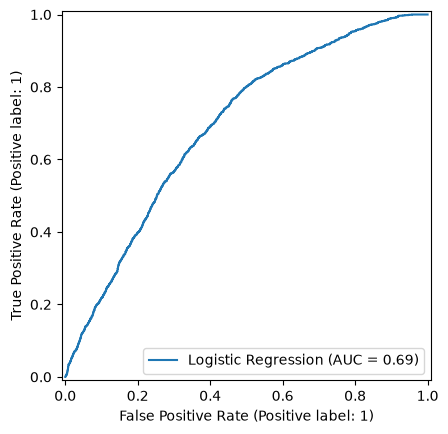

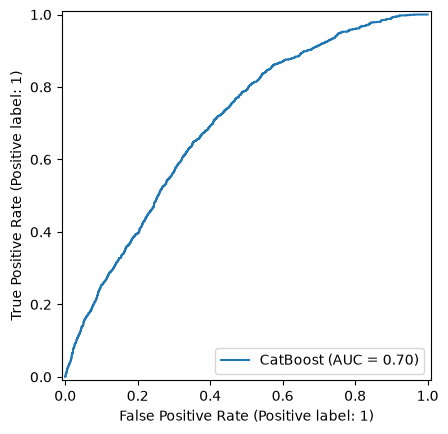

In [100]:
import matplotlib.pyplot as plt

from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(
    y_val,
    val_prob,
    name="Logistic Regression"
)

RocCurveDisplay.from_predictions(
    y_val_cb,
    cat_val_prob,
    name="CatBoost"
)

plt.show()

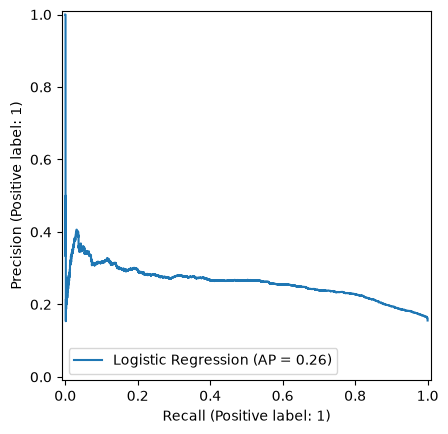

In [101]:
from sklearn.metrics import PrecisionRecallDisplay

PrecisionRecallDisplay.from_predictions(
    y_val,
    val_prob,
    name="Logistic Regression"
)

plt.show()

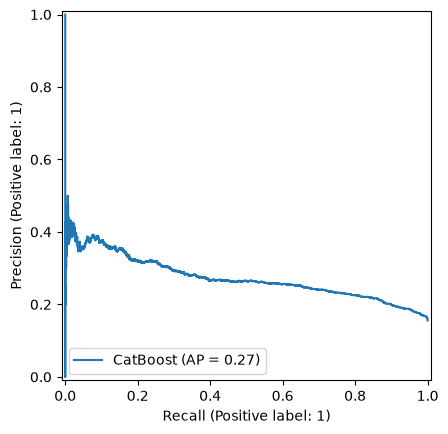

In [102]:
PrecisionRecallDisplay.from_predictions(
    y_val_cb,
    cat_val_prob,
    name="CatBoost"
)

plt.show()

In [103]:
importance = pd.DataFrame({
    "feature": features,
    "importance": cat_model.get_feature_importance()
})

importance = importance.sort_values(
    "importance",
    ascending=False
)

importance.head(20)

,feature,importance
16,prev_switched_off_rate,23.482439
10,prev_switched_off_count,12.936579
5,prev_rpc_rate,10.773317
13,prev_no_answer_rate,4.899810
0,hour,4.883181
32,source,4.232522
12,prev_answer_rate,3.422616
14,prev_rejected_rate,3.010316
19,days_since_last_rpc,2.938808
33,relation_recorded,2.573871


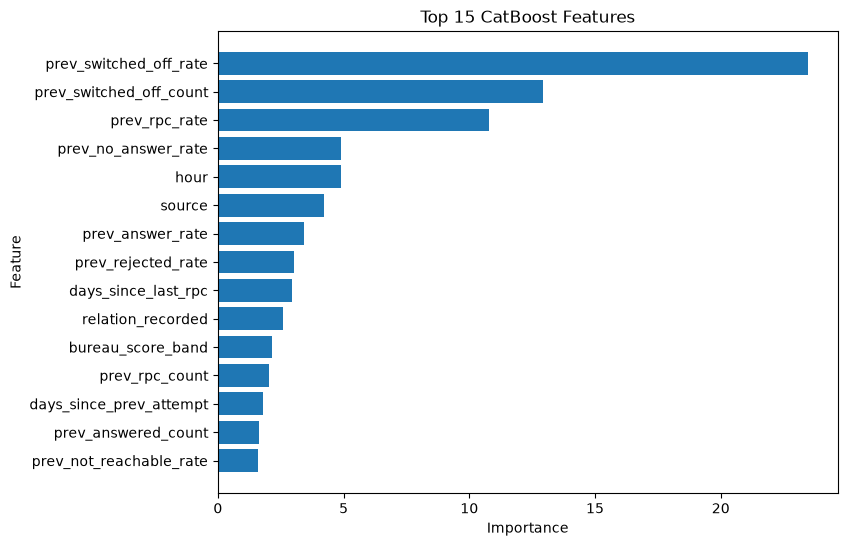

In [104]:
top_features = importance.head(15)

plt.figure(figsize=(8, 6))

plt.barh(
    top_features["feature"][::-1],
    top_features["importance"][::-1]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 15 CatBoost Features")

plt.show()

In [105]:
importance.head(30)

,feature,importance
16,prev_switched_off_rate,23.482439
10,prev_switched_off_count,12.936579
5,prev_rpc_rate,10.773317
13,prev_no_answer_rate,4.899810
0,hour,4.883181
32,source,4.232522
12,prev_answer_rate,3.422616
14,prev_rejected_rate,3.010316
19,days_since_last_rpc,2.938808
33,relation_recorded,2.573871


In [106]:
logistic_model.fit(
    X_train,
    y_train
)

print("Logistic Regression trained successfully")

Logistic Regression trained successfully


In [107]:
val_prob = logistic_model.predict_proba(
    X_val
)[:, 1]

val_prob[:10]

array([0.20709745, 0.17297117, 0.23939912, 0.23949344, 0.22840861,
       0.22672208, 0.20126575, 0.21503389, 0.21587564, 0.28726805])

In [108]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)

roc_auc = roc_auc_score(
    y_val,
    val_prob
)

pr_auc = average_precision_score(
    y_val,
    val_prob
)

brier = brier_score_loss(
    y_val,
    val_prob
)

print("LOGISTIC REGRESSION")
print("ROC-AUC :", round(roc_auc, 4))
print("PR-AUC  :", round(pr_auc, 4))
print("Brier   :", round(brier, 4))

LOGISTIC REGRESSION
ROC-AUC : 0.6915
PR-AUC  : 0.2606
Brier   : 0.1239


In [109]:
rpc_prevalence = y_val.mean()

print(
    "RPC prevalence:",
    round(rpc_prevalence, 4)
)

RPC prevalence: 0.1556


In [110]:
from catboost import CatBoostClassifier

In [111]:
X_train_cb = train_df[features].copy()
X_val_cb = val_df[features].copy()
X_test_cb = test_df[features].copy()

y_train_cb = train_df[target].copy()
y_val_cb = val_df[target].copy()
y_test_cb = test_df[target].copy()

print(X_train_cb.shape)
print(X_val_cb.shape)
print(X_test_cb.shape)

(35797, 43)
(7860, 43)
(7404, 43)


In [112]:
for col in categorical_features:

    X_train_cb[col] = (
        X_train_cb[col]
        .fillna("missing")
        .astype(str)
    )

    X_val_cb[col] = (
        X_val_cb[col]
        .fillna("missing")
        .astype(str)
    )

    X_test_cb[col] = (
        X_test_cb[col]
        .fillna("missing")
        .astype(str)
    )

In [113]:
for col in numeric_features:

    X_train_cb[col] = pd.to_numeric(
        X_train_cb[col],
        errors="coerce"
    )

    X_val_cb[col] = pd.to_numeric(
        X_val_cb[col],
        errors="coerce"
    )

    X_test_cb[col] = pd.to_numeric(
        X_test_cb[col],
        errors="coerce"
    )

In [114]:
cat_model = CatBoostClassifier(
    iterations=1000,
    depth=6,
    learning_rate=0.05,
    loss_function="Logloss",
    eval_metric="AUC",
    l2_leaf_reg=5,
    random_seed=42,
    verbose=100,
    allow_writing_files=False
)

In [115]:
cat_model.fit(
    X_train_cb,
    y_train_cb,

    cat_features=categorical_features,

    eval_set=(
        X_val_cb,
        y_val_cb
    ),

    early_stopping_rounds=100,

    use_best_model=True
)

0:	test: 0.5633847	best: 0.5633847 (0)	total: 56.6ms	remaining: 56.5s
100:	test: 0.6955779	best: 0.6955801 (98)	total: 9.79s	remaining: 1m 27s
200:	test: 0.6971451	best: 0.6972487 (178)	total: 18.9s	remaining: 1m 15s
300:	test: 0.6967631	best: 0.6973179 (211)	total: 29.2s	remaining: 1m 7s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.6973179052
bestIteration = 211

Shrink model to first 212 iterations.


CatBoostClassifier(allow_writing_files=False, depth=6, eval_metric='AUC', iterations=1000, l2_leaf_reg=5, learning_rate=0.05, loss_function='Logloss', random_seed=42, verbose=100)

In [116]:
cat_val_prob = cat_model.predict_proba(
    X_val_cb
)[:, 1]

cat_val_prob[:10]

array([0.18756809, 0.1853543 , 0.24029862, 0.21953184, 0.19176192,
       0.19228425, 0.1988504 , 0.22290466, 0.14700686, 0.20093246])

In [117]:
cat_roc_auc = roc_auc_score(
    y_val_cb,
    cat_val_prob
)

cat_pr_auc = average_precision_score(
    y_val_cb,
    cat_val_prob
)

cat_brier = brier_score_loss(
    y_val_cb,
    cat_val_prob
)

print("CATBOOST")
print("ROC-AUC :", round(cat_roc_auc, 4))
print("PR-AUC  :", round(cat_pr_auc, 4))
print("Brier   :", round(cat_brier, 4))

CATBOOST
ROC-AUC : 0.6973
PR-AUC  : 0.2733
Brier   : 0.1231


In [118]:
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "CatBoost"
    ],

    "ROC_AUC": [
        roc_auc,
        cat_roc_auc
    ],

    "PR_AUC": [
        pr_auc,
        cat_pr_auc
    ],

    "Brier": [
        brier,
        cat_brier
    ]
})

comparison

,Model,ROC_AUC,PR_AUC,Brier
0,Logistic Regression,0.691542,0.260583,0.123928
1,CatBoost,0.697318,0.273330,0.123109


In [119]:
importance = pd.DataFrame({
    "feature": features,
    "importance": cat_model.get_feature_importance()
})

importance = importance.sort_values(
    "importance",
    ascending=False
)

importance.head(20)

,feature,importance
16,prev_switched_off_rate,23.482439
10,prev_switched_off_count,12.936579
5,prev_rpc_rate,10.773317
13,prev_no_answer_rate,4.899810
0,hour,4.883181
32,source,4.232522
12,prev_answer_rate,3.422616
14,prev_rejected_rate,3.010316
19,days_since_last_rpc,2.938808
33,relation_recorded,2.573871


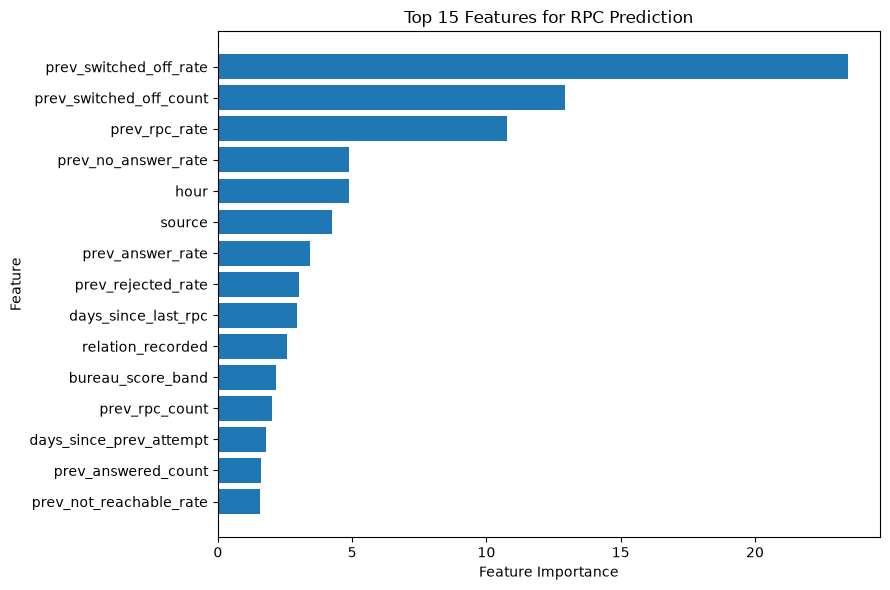

In [120]:
import matplotlib.pyplot as plt

top_features = importance.head(15)

plt.figure(figsize=(9, 6))

plt.barh(
    top_features["feature"][::-1],
    top_features["importance"][::-1]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 15 Features for RPC Prediction")

plt.tight_layout()
plt.show()

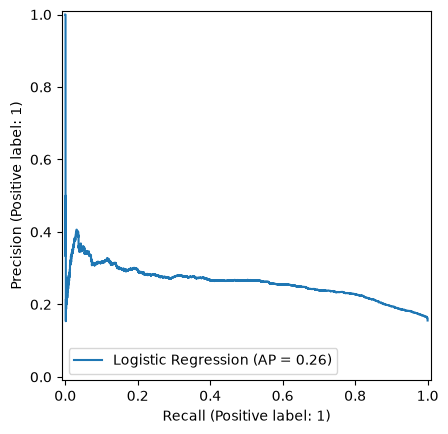

In [121]:
from sklearn.metrics import PrecisionRecallDisplay

PrecisionRecallDisplay.from_predictions(
    y_val,
    val_prob,
    name="Logistic Regression"
)

plt.show()

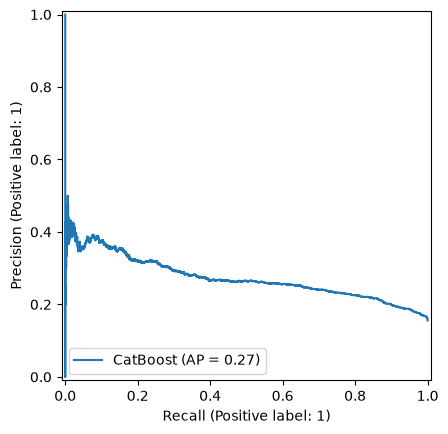

In [122]:
PrecisionRecallDisplay.from_predictions(
    y_val_cb,
    cat_val_prob,
    name="CatBoost"
)

plt.show()

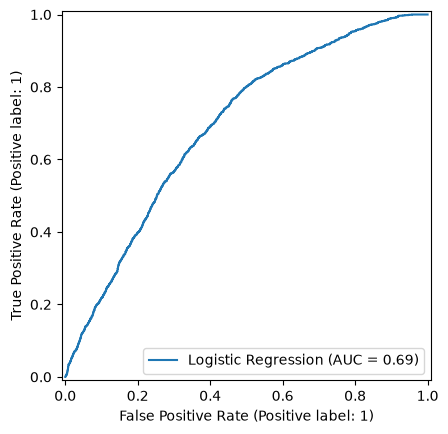

In [123]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(
    y_val,
    val_prob,
    name="Logistic Regression"
)

plt.show()

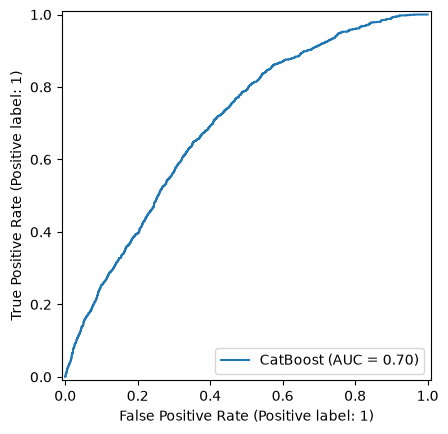

In [124]:
RocCurveDisplay.from_predictions(
    y_val_cb,
    cat_val_prob,
    name="CatBoost"
)

plt.show()

In [125]:
X_test
X_test_cb

,hour,day_of_week,is_weekend,prev_attempts,prev_rpc_count,prev_rpc_rate,prev_answered_count,prev_no_answer_count,prev_rejected_count,prev_not_reachable_count,...,relation_recorded,lender_id,portfolio,income_type,town_id,preferred_language,bucket_start,bureau_score_band,paid_other_lenders_30d,last_bounce_reason
296,10,3,0,0,0.0,0.000000,0.0,0.0,0.0,0.0,...,self,L05,msme,self_employed,T3,hinglish,1-30,550-649,False,insufficient_funds
297,9,4,0,1,0.0,0.000000,0.0,1.0,0.0,0.0,...,self,L05,msme,self_employed,T3,hinglish,1-30,550-649,False,insufficient_funds
298,9,0,0,2,0.0,0.000000,0.0,2.0,0.0,0.0,...,self,L05,msme,self_employed,T3,hinglish,1-30,550-649,False,insufficient_funds
299,12,5,1,3,0.0,0.000000,0.0,2.0,1.0,0.0,...,self,L05,msme,self_employed,T3,hinglish,1-30,550-649,False,insufficient_funds
300,11,4,0,4,1.0,0.250000,1.0,2.0,1.0,0.0,...,self,L05,msme,self_employed,T3,hinglish,1-30,550-649,False,insufficient_funds
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50999,14,5,1,21,3.0,0.142857,3.0,13.0,5.0,0.0,...,self,L06,two_wheeler,salaried,T3,hinglish,X,550-649,True,insufficient_funds
51000,9,0,0,22,3.0,0.136364,3.0,14.0,5.0,0.0,...,self,L06,two_wheeler,salaried,T3,hinglish,X,550-649,True,insufficient_funds
51001,16,0,0,23,3.0,0.130435,3.0,14.0,6.0,0.0,...,self,L06,two_wheeler,salaried,T3,hinglish,X,550-649,True,insufficient_funds
51059,11,4,0,0,0.0,0.000000,0.0,0.0,0.0,0.0,...,self,L03,pl_salaried,salaried,T1,hinglish,90+,300-549,False,insufficient_funds


In [126]:
importance.head(15)

,feature,importance
16,prev_switched_off_rate,23.482439
10,prev_switched_off_count,12.936579
5,prev_rpc_rate,10.773317
13,prev_no_answer_rate,4.899810
0,hour,4.883181
32,source,4.232522
12,prev_answer_rate,3.422616
14,prev_rejected_rate,3.010316
19,days_since_last_rpc,2.938808
33,relation_recorded,2.573871


In [127]:
if cat_pr_auc > pr_auc:
    best_model_name = "CatBoost"
else:
    best_model_name = "Logistic Regression"

print("Selected model:", best_model_name)
print("Logistic PR-AUC:", round(pr_auc, 4))
print("CatBoost PR-AUC:", round(cat_pr_auc, 4))

Selected model: CatBoost
Logistic PR-AUC: 0.2606
CatBoost PR-AUC: 0.2733


In [128]:
df["attempt_ts"] = pd.to_datetime(df["attempt_ts"])
df["added_date"] = pd.to_datetime(df["added_date"])

In [129]:
latest_idx = (
    df.groupby(["account_id", "phone_id"])["attempt_ts"]
      .idxmax()
)

current_state = (
    df.loc[latest_idx]
      .copy()
      .reset_index(drop=True)
)

print("Number of borrower-phone combinations:",
      len(current_state))

current_state[
    ["account_id", "phone_id", "attempt_ts", "is_rpc"]
].head()

Number of borrower-phone combinations: 4034


,account_id,phone_id,attempt_ts,is_rpc
0,AC000001,PH000611,2026-04-18 12:23:40,0
1,AC000001,PH000612,2026-05-13 11:58:13,0
2,AC000002,PH000613,2026-04-02 10:55:33,0
3,AC000003,PH000615,2026-04-04 08:20:48,1
4,AC000004,PH000618,2026-04-08 09:43:18,1


In [130]:
current_state["prev_attempts"] = (
    current_state["prev_attempts"] + 1
)

In [131]:
current_state["prev_rpc_count"] = (
    current_state["prev_rpc_count"]
    + current_state["is_rpc"]
)

current_state["prev_rpc_rate"] = (
    current_state["prev_rpc_count"]
    / current_state["prev_attempts"]
)

In [132]:
current_state["prev_answered_count"] += (
    current_state["network_response"] == "answered"
).astype(int)

current_state["prev_no_answer_count"] += (
    current_state["network_response"] == "ring_no_answer"
).astype(int)

current_state["prev_rejected_count"] += (
    current_state["network_response"] == "busy_rejected"
).astype(int)

current_state["prev_not_reachable_count"] += (
    current_state["network_response"] == "not_reachable"
).astype(int)

current_state["prev_switched_off_count"] += (
    current_state["network_response"] == "switched_off"
).astype(int)

current_state["prev_invalid_network_count"] += (
    current_state["network_response"] == "number_does_not_exist"
).astype(int)

In [133]:
denom = current_state["prev_attempts"]

current_state["prev_answer_rate"] = (
    current_state["prev_answered_count"] / denom
)

current_state["prev_no_answer_rate"] = (
    current_state["prev_no_answer_count"] / denom
)

current_state["prev_rejected_rate"] = (
    current_state["prev_rejected_count"] / denom
)

current_state["prev_not_reachable_rate"] = (
    current_state["prev_not_reachable_count"] / denom
)

current_state["prev_switched_off_rate"] = (
    current_state["prev_switched_off_count"] / denom
)

current_state["prev_invalid_network_rate"] = (
    current_state["prev_invalid_network_count"] / denom
)

current_state["prev_failure_rate"] = (
    1 - current_state["prev_rpc_rate"]
)

In [134]:
latest_time = df["attempt_ts"].max()

scoring_date = (
    latest_time.normalize()
    + pd.Timedelta(days=1)
)

scoring_ts = (
    scoring_date
    + pd.Timedelta(hours=10)
)

print("Next scoring time:", scoring_ts)

Next scoring time: 2026-06-30 10:00:00


In [135]:
current_state["hour"] = scoring_ts.hour

current_state["day_of_week"] = scoring_ts.dayofweek

current_state["is_weekend"] = int(
    scoring_ts.dayofweek >= 5
)

In [136]:
def get_time_slot(hour):
    if hour < 12:
        return "morning"
    elif hour < 17:
        return "afternoon"
    else:
        return "evening"

current_state["time_slot"] = get_time_slot(
    scoring_ts.hour
)

In [137]:
current_state["days_since_prev_attempt"] = (
    scoring_ts - current_state["attempt_ts"]
).dt.total_seconds() / 86400

In [138]:
rpc_history = (
    df[df["is_rpc"] == 1]
    .groupby(["account_id", "phone_id"])["attempt_ts"]
    .max()
    .rename("latest_rpc_ts")
    .reset_index()
)

In [139]:
current_state = current_state.merge(
    rpc_history,
    on=["account_id", "phone_id"],
    how="left"
)

In [140]:
current_state["days_since_last_rpc"] = (
    scoring_ts - current_state["latest_rpc_ts"]
).dt.total_seconds() / 86400

current_state["days_since_last_rpc"] = (
    current_state["days_since_last_rpc"]
    .fillna(-1)
)

In [141]:
current_state["phone_age_days"] = (
    scoring_ts - current_state["added_date"]
).dt.days

In [142]:
X_current = current_state[features].copy()

print(X_current.shape)
X_current.head()

(4034, 43)


,hour,day_of_week,is_weekend,prev_attempts,prev_rpc_count,prev_rpc_rate,prev_answered_count,prev_no_answer_count,prev_rejected_count,prev_not_reachable_count,...,relation_recorded,lender_id,portfolio,income_type,town_id,preferred_language,bucket_start,bureau_score_band,paid_other_lenders_30d,last_bounce_reason
0,10,1,0,8,0.0,0.0,0.0,0.0,0.0,5.0,...,self,L03,pl_salaried,salaried,T1,kanglish,61-90,550-649,False,mandate_not_registered
1,10,1,0,7,0.0,0.0,3.0,3.0,1.0,0.0,...,self,L03,pl_salaried,salaried,T1,kanglish,61-90,550-649,False,mandate_not_registered
2,10,1,0,1,0.0,0.0,0.0,1.0,0.0,0.0,...,self,L03,pl_salaried,salaried,T3,english,X,650-699,False,insufficient_funds
3,10,1,0,5,1.0,0.2,1.0,4.0,0.0,0.0,...,self,L06,msme,self_employed,T2,hinglish,61-90,300-549,False,insufficient_funds
4,10,1,0,5,1.0,0.2,1.0,3.0,1.0,0.0,...,self,L01,credit_card,self_employed,T2,hinglish,61-90,300-549,False,insufficient_funds


In [143]:
if best_model_name == "CatBoost":

    X_current_model = X_current.copy()

    for col in categorical_features:
        X_current_model[col] = (
            X_current_model[col]
            .fillna("missing")
            .astype(str)
        )

    for col in numeric_features:
        X_current_model[col] = pd.to_numeric(
            X_current_model[col],
            errors="coerce"
        )

    current_state["rpc_probability"] = (
        cat_model.predict_proba(
            X_current_model
        )[:, 1]
    )

else:

    current_state["rpc_probability"] = (
        logistic_model.predict_proba(
            X_current
        )[:, 1]
    )

In [144]:
current_state[
    [
        "account_id",
        "phone_id",
        "source",
        "relation_recorded",
        "prev_attempts",
        "prev_rpc_rate",
        "rpc_probability"
    ]
].head(20)

,account_id,phone_id,source,relation_recorded,prev_attempts,prev_rpc_rate,rpc_probability
0,AC000001,PH000611,kyc_origination,self,8,0.000000,0.010295
1,AC000001,PH000612,bureau,self,7,0.000000,0.052531
2,AC000002,PH000613,kyc_origination,self,1,0.000000,0.229406
3,AC000003,PH000615,kyc_origination,self,5,0.200000,0.280563
4,AC000004,PH000618,kyc_origination,self,5,0.200000,0.202068
5,AC000005,PH000620,kyc_origination,self,57,0.245614,0.212503
6,AC000006,PH000622,kyc_origination,self,8,0.250000,0.192037
7,AC000007,PH000625,kyc_origination,self,2,0.500000,0.129772
8,AC000007,PH000626,reference,reference_spouse,2,0.000000,0.051962
9,AC000008,PH000627,kyc_origination,self,8,0.375000,0.263699


In [145]:
current_state["phone_rank"] = (
    current_state
    .groupby("account_id")["rpc_probability"]
    .rank(
        method="first",
        ascending=False
    )
)

In [146]:
current_state["phone_rank"] = (
    current_state["phone_rank"]
    .astype(int)
)

In [147]:
phone_ranking = (
    current_state[
        [
            "account_id",
            "phone_id",
            "source",
            "relation_recorded",
            "priority_slot",
            "prev_attempts",
            "prev_rpc_rate",
            "prev_answer_rate",
            "prev_invalid_network_rate",
            "rpc_probability",
            "phone_rank"
        ]
    ]
    .sort_values(
        ["account_id", "phone_rank"]
    )
)

phone_ranking.head(30)

,account_id,phone_id,source,relation_recorded,priority_slot,prev_attempts,prev_rpc_rate,prev_answer_rate,prev_invalid_network_rate,rpc_probability,phone_rank
1,AC000001,PH000612,bureau,self,1,7,0.000000,0.428571,0.0,0.052531,1
0,AC000001,PH000611,kyc_origination,self,0,8,0.000000,0.000000,0.0,0.010295,2
2,AC000002,PH000613,kyc_origination,self,0,1,0.000000,0.000000,0.0,0.229406,1
3,AC000003,PH000615,kyc_origination,self,0,5,0.200000,0.200000,0.0,0.280563,1
4,AC000004,PH000618,kyc_origination,self,0,5,0.200000,0.200000,0.0,0.202068,1
5,AC000005,PH000620,kyc_origination,self,0,57,0.245614,0.263158,0.0,0.212503,1
6,AC000006,PH000622,kyc_origination,self,0,8,0.250000,0.250000,0.0,0.192037,1
7,AC000007,PH000625,kyc_origination,self,0,2,0.500000,0.500000,0.0,0.129772,1
8,AC000007,PH000626,reference,reference_spouse,1,2,0.000000,0.500000,0.0,0.051962,2
9,AC000008,PH000627,kyc_origination,self,0,8,0.375000,0.375000,0.0,0.263699,1


In [148]:
phone_counts = (
    phone_ranking
    .groupby("account_id")
    .size()
)

multi_phone_accounts = (
    phone_counts[
        phone_counts >= 2
    ]
)

multi_phone_accounts.head()

account_id
AC000001    2
AC000007    2
AC000009    2
AC000011    2
AC000012    2
dtype: int64

In [149]:
example_account = (
    multi_phone_accounts
    .index[0]
)

print("Account:", example_account)

phone_ranking[
    phone_ranking["account_id"]
    == example_account
]

Account: AC000001


,account_id,phone_id,source,relation_recorded,priority_slot,prev_attempts,prev_rpc_rate,prev_answer_rate,prev_invalid_network_rate,rpc_probability,phone_rank
1,AC000001,PH000612,bureau,self,1,7,0.0,0.428571,0.0,0.052531,1
0,AC000001,PH000611,kyc_origination,self,0,8,0.0,0.000000,0.0,0.010295,2


In [150]:
example_account = (
    multi_phone_accounts
    .index[0]
)

print("Account:", example_account)

phone_ranking[
    phone_ranking["account_id"]
    == example_account
]

Account: AC000001


,account_id,phone_id,source,relation_recorded,priority_slot,prev_attempts,prev_rpc_rate,prev_answer_rate,prev_invalid_network_rate,rpc_probability,phone_rank
1,AC000001,PH000612,bureau,self,1,7,0.0,0.428571,0.0,0.052531,1
0,AC000001,PH000611,kyc_origination,self,0,8,0.0,0.000000,0.0,0.010295,2


In [151]:
first_call_recommendation = (
    phone_ranking[
        phone_ranking["phone_rank"] == 1
    ]
    .copy()
)

In [152]:
first_call_recommendation.head(20)

,account_id,phone_id,source,relation_recorded,priority_slot,prev_attempts,prev_rpc_rate,prev_answer_rate,prev_invalid_network_rate,rpc_probability,phone_rank
1,AC000001,PH000612,bureau,self,1,7,0.000000,0.428571,0.0,0.052531,1
2,AC000002,PH000613,kyc_origination,self,0,1,0.000000,0.000000,0.0,0.229406,1
3,AC000003,PH000615,kyc_origination,self,0,5,0.200000,0.200000,0.0,0.280563,1
4,AC000004,PH000618,kyc_origination,self,0,5,0.200000,0.200000,0.0,0.202068,1
5,AC000005,PH000620,kyc_origination,self,0,57,0.245614,0.263158,0.0,0.212503,1
6,AC000006,PH000622,kyc_origination,self,0,8,0.250000,0.250000,0.0,0.192037,1
7,AC000007,PH000625,kyc_origination,self,0,2,0.500000,0.500000,0.0,0.129772,1
9,AC000008,PH000627,kyc_origination,self,0,8,0.375000,0.375000,0.0,0.263699,1
11,AC000009,PH000631,bureau,self,1,18,0.222222,0.222222,0.0,0.188493,1
12,AC000010,PH000632,kyc_origination,self,0,14,0.500000,0.500000,0.0,0.221965,1


In [153]:
first_call_recommendation["recommendation"] = (
    "Call "
    + first_call_recommendation["phone_id"].astype(str)
    + " first"
)

In [154]:
first_call_recommendation[
    [
        "account_id",
        "phone_id",
        "rpc_probability",
        "recommendation"
    ]
].head(20)

,account_id,phone_id,rpc_probability,recommendation
1,AC000001,PH000612,0.052531,Call PH000612 first
2,AC000002,PH000613,0.229406,Call PH000613 first
3,AC000003,PH000615,0.280563,Call PH000615 first
4,AC000004,PH000618,0.202068,Call PH000618 first
5,AC000005,PH000620,0.212503,Call PH000620 first
6,AC000006,PH000622,0.192037,Call PH000622 first
7,AC000007,PH000625,0.129772,Call PH000625 first
9,AC000008,PH000627,0.263699,Call PH000627 first
11,AC000009,PH000631,0.188493,Call PH000631 first
12,AC000010,PH000632,0.221965,Call PH000632 first


In [155]:
phone_ranking.to_csv(
    "../data/phone_rpc_ranking.csv",
    index=False
)

first_call_recommendation.to_csv(
    "../data/first_call_recommendation.csv",
    index=False
)

print("Ranking files saved successfully.")

Ranking files saved successfully.


In [159]:
import os

print("Current folder:")
print(os.getcwd())

print("\nFiles Python can see:")
print(os.listdir("../data"))

Current folder:
c:\Users\LENOVO\Videos\tre\PS2_CreditNirvana\notebooks

Files Python can see:
['accounts.csv', 'addresses.csv', 'agents.csv', 'dial_attempts.csv', 'dial_attempts_with_target.csv', 'field_visits.csv', 'first_call_recommendation.csv', 'lenders.csv', 'payments.csv', 'phone_contacts.csv', 'phone_rpc_ranking.csv', 'rpc_feature_table.csv', 'skip_trace.csv', 'splits.csv', 'verified_phone_states.csv']


In [160]:
import pandas as pd
import numpy as np

dial = pd.read_csv(
    "../data/dial_attempts_with_target.csv"
)

verified = pd.read_csv(
    "../data/verified_phone_states.csv"
)

phones = pd.read_csv(
    "../data/phone_contacts.csv"
)

dial["attempt_ts"] = pd.to_datetime(
    dial["attempt_ts"]
)

verified["verified_date"] = pd.to_datetime(
    verified["verified_date"]
)

phones["added_date"] = pd.to_datetime(
    phones["added_date"]
)

print("Dial attempts:", dial.shape)
print("Verified states:", verified.shape)
print("Phones:", phones.shape)

Dial attempts: (51061, 17)
Verified states: (250, 4)
Phones: (5719, 7)


In [161]:
verified["verified_status"].value_counts()

verified_status
borrower_number        127
third_party_number      74
not_borrower_number     27
switched_off            19
invalid_number           3
Name: count, dtype: int64

In [162]:
print(
    verified["verified_status"]
    .value_counts(normalize=True)
    .round(3)
)

verified_status
borrower_number        0.508
third_party_number     0.296
not_borrower_number    0.108
switched_off           0.076
invalid_number         0.012
Name: proportion, dtype: float64


In [163]:
verified = (
    verified
    .sort_values("verified_date")
    .drop_duplicates(
        subset=["account_id", "phone_id"],
        keep="last"
    )
    .reset_index(drop=True)
)

print("Unique verified phones:", len(verified))

Unique verified phones: 250


In [164]:
hist = dial.merge(
    verified[
        [
            "account_id",
            "phone_id",
            "verified_status",
            "verified_date"
        ]
    ],
    on=["account_id", "phone_id"],
    how="inner"
)

print(hist.shape)

(2189, 19)


In [165]:
hist = hist[
    hist["attempt_ts"] < hist["verified_date"]
].copy()

print("Historical attempts before verification:", hist.shape)

Historical attempts before verification: (2189, 19)


In [166]:
hist["flag_rpc"] = hist["is_rpc"].astype(int)

hist["flag_answered"] = (
    hist["network_response"] == "answered"
).astype(int)

hist["flag_no_answer"] = (
    hist["network_response"] == "ring_no_answer"
).astype(int)

hist["flag_rejected"] = (
    hist["network_response"] == "busy_rejected"
).astype(int)

hist["flag_not_reachable"] = (
    hist["network_response"] == "not_reachable"
).astype(int)

hist["flag_switched_off"] = (
    hist["network_response"] == "switched_off"
).astype(int)

hist["flag_invalid_network"] = (
    hist["network_response"] == "number_does_not_exist"
).astype(int)

In [167]:
hist["flag_third_party"] = (
    hist["disposition"].isin(
        [
            "third_party_contact",
            "third_party_ptp"
        ]
    )
).astype(int)

hist["flag_wrong_number"] = (
    hist["disposition"] == "wrong_number"
).astype(int)

hist["flag_invalid_disposition"] = (
    hist["disposition"] == "invalid_number"
).astype(int)

In [168]:
phone_history = (
    hist
    .groupby(
        [
            "account_id",
            "phone_id",
            "verified_status",
            "verified_date"
        ]
    )
    .agg(

        hist_attempts=(
            "attempt_id",
            "count"
        ),

        hist_rpc_count=(
            "flag_rpc",
            "sum"
        ),

        hist_answered_count=(
            "flag_answered",
            "sum"
        ),

        hist_no_answer_count=(
            "flag_no_answer",
            "sum"
        ),

        hist_rejected_count=(
            "flag_rejected",
            "sum"
        ),

        hist_not_reachable_count=(
            "flag_not_reachable",
            "sum"
        ),

        hist_switched_off_count=(
            "flag_switched_off",
            "sum"
        ),

        hist_invalid_network_count=(
            "flag_invalid_network",
            "sum"
        ),

        hist_third_party_count=(
            "flag_third_party",
            "sum"
        ),

        hist_wrong_number_count=(
            "flag_wrong_number",
            "sum"
        ),

        hist_invalid_disposition_count=(
            "flag_invalid_disposition",
            "sum"
        ),

        last_attempt_ts=(
            "attempt_ts",
            "max"
        )
    )
    .reset_index()
)

phone_history.head()

,account_id,phone_id,verified_status,verified_date,hist_attempts,hist_rpc_count,hist_answered_count,hist_no_answer_count,hist_rejected_count,hist_not_reachable_count,hist_switched_off_count,hist_invalid_network_count,hist_third_party_count,hist_wrong_number_count,hist_invalid_disposition_count,last_attempt_ts
0,AC000004,PH000618,borrower_number,2026-07-02,5,1,1,3,1,0,0,0,0,0,0,2026-04-08 09:43:18
1,AC000007,PH000625,borrower_number,2026-07-02,2,1,1,0,1,0,0,0,0,0,0,2026-04-04 15:18:44
2,AC000027,PH000671,not_borrower_number,2026-07-02,18,6,6,11,0,1,0,0,0,0,0,2026-05-25 12:31:13
3,AC000032,PH000685,switched_off,2026-07-02,8,0,0,0,0,4,4,0,0,0,0,2026-05-04 15:06:59
4,AC000032,PH000686,borrower_number,2026-07-02,3,2,2,1,0,0,0,0,0,0,0,2026-05-13 11:25:40


In [169]:
state_df = verified.merge(
    phone_history,
    on=[
        "account_id",
        "phone_id",
        "verified_status",
        "verified_date"
    ],
    how="left"
)

print(state_df.shape)

(250, 16)


In [170]:
count_features = [
    "hist_attempts",
    "hist_rpc_count",
    "hist_answered_count",
    "hist_no_answer_count",
    "hist_rejected_count",
    "hist_not_reachable_count",
    "hist_switched_off_count",
    "hist_invalid_network_count",
    "hist_third_party_count",
    "hist_wrong_number_count",
    "hist_invalid_disposition_count"
]

state_df[count_features] = (
    state_df[count_features]
    .fillna(0)
)

In [171]:
denom = (
    state_df["hist_attempts"]
    .replace(0, np.nan)
)

state_df["hist_rpc_rate"] = (
    state_df["hist_rpc_count"] / denom
).fillna(0)

state_df["hist_answer_rate"] = (
    state_df["hist_answered_count"] / denom
).fillna(0)

state_df["hist_no_answer_rate"] = (
    state_df["hist_no_answer_count"] / denom
).fillna(0)

state_df["hist_rejected_rate"] = (
    state_df["hist_rejected_count"] / denom
).fillna(0)

state_df["hist_not_reachable_rate"] = (
    state_df["hist_not_reachable_count"] / denom
).fillna(0)

state_df["hist_switched_off_rate"] = (
    state_df["hist_switched_off_count"] / denom
).fillna(0)

state_df["hist_invalid_network_rate"] = (
    state_df["hist_invalid_network_count"] / denom
).fillna(0)

state_df["hist_third_party_rate"] = (
    state_df["hist_third_party_count"] / denom
).fillna(0)

state_df["hist_wrong_number_rate"] = (
    state_df["hist_wrong_number_count"] / denom
).fillna(0)

In [172]:
state_df["days_since_last_attempt"] = (
    state_df["verified_date"]
    - state_df["last_attempt_ts"]
).dt.total_seconds() / 86400

state_df["days_since_last_attempt"] = (
    state_df["days_since_last_attempt"]
    .fillna(-1)
)

In [173]:
state_df = state_df.merge(
    phones[
        [
            "account_id",
            "phone_id",
            "source",
            "relation_recorded",
            "priority_slot"
        ]
    ],
    on=["account_id", "phone_id"],
    how="left",
    validate="many_to_one"
)

In [174]:
state_numeric_features = [

    "hist_attempts",

    "hist_rpc_count",
    "hist_answered_count",

    "hist_no_answer_count",
    "hist_rejected_count",
    "hist_not_reachable_count",
    "hist_switched_off_count",

    "hist_invalid_network_count",
    "hist_third_party_count",
    "hist_wrong_number_count",
    "hist_invalid_disposition_count",

    "hist_rpc_rate",
    "hist_answer_rate",
    "hist_no_answer_rate",
    "hist_rejected_rate",
    "hist_not_reachable_rate",
    "hist_switched_off_rate",
    "hist_invalid_network_rate",
    "hist_third_party_rate",
    "hist_wrong_number_rate",

    "days_since_last_attempt",

    "priority_slot"
]

In [175]:
state_categorical_features = [
    "source",
    "relation_recorded"
]

In [176]:
state_features = (
    state_numeric_features
    + state_categorical_features
)

state_target = "verified_status"

In [177]:
missing = [
    col
    for col in state_features
    if col not in state_df.columns
]

print("Missing:", missing)

Missing: []


In [178]:
X = state_df[state_features].copy()
y = state_df[state_target].copy()

In [179]:
for col in state_categorical_features:
    X[col] = (
        X[col]
        .fillna("missing")
        .astype(str)
    )

In [180]:
for col in state_numeric_features:
    X[col] = pd.to_numeric(
        X[col],
        errors="coerce"
    )

In [181]:
class_counts = y.value_counts()

print(class_counts)
print()
print("Minimum class size:",
      class_counts.min())

verified_status
borrower_number        127
third_party_number      74
not_borrower_number     27
switched_off            19
invalid_number           3
Name: count, dtype: int64

Minimum class size: 3


In [182]:
from sklearn.model_selection import train_test_split

if class_counts.min() < 2:
    raise ValueError(
        "At least one contact-state class has fewer than "
        "2 examples. Do not train yet."
    )

X_train_state, X_val_state, y_train_state, y_val_state = (
    train_test_split(
        X,
        y,
        test_size=0.25,
        random_state=42,
        stratify=y
    )
)

print("Train:", X_train_state.shape)
print("Validation:", X_val_state.shape)

Train: (187, 24)
Validation: (63, 24)


In [183]:
from catboost import CatBoostClassifier

In [184]:
state_model = CatBoostClassifier(

    iterations=600,

    depth=5,

    learning_rate=0.05,

    loss_function="MultiClass",

    eval_metric="TotalF1",

    auto_class_weights="Balanced",

    random_seed=42,

    verbose=50,

    allow_writing_files=False
)

In [185]:
state_model.fit(

    X_train_state,
    y_train_state,

    cat_features=state_categorical_features,

    eval_set=(
        X_val_state,
        y_val_state
    ),

    early_stopping_rounds=80,

    use_best_model=True
)

0:	learn: 0.6405005	test: 0.6188861	best: 0.6188861 (0)	total: 35.3ms	remaining: 21.2s
50:	learn: 0.8397083	test: 0.7370407	best: 0.7478354 (21)	total: 1.71s	remaining: 18.4s
100:	learn: 0.8417553	test: 0.7662123	best: 0.7662123 (89)	total: 5.55s	remaining: 27.4s
150:	learn: 0.8574179	test: 0.7664773	best: 0.7664773 (135)	total: 7.5s	remaining: 22.3s
200:	learn: 0.9061527	test: 0.7723362	best: 0.7723362 (196)	total: 9.15s	remaining: 18.2s
250:	learn: 0.9339922	test: 0.7553629	best: 0.7937253 (201)	total: 13.2s	remaining: 18.3s
Stopped by overfitting detector  (80 iterations wait)

bestTest = 0.793725339
bestIteration = 201

Shrink model to first 202 iterations.


CatBoostClassifier(allow_writing_files=False, auto_class_weights='Balanced', depth=5, eval_metric='TotalF1', iterations=600, learning_rate=0.05, loss_function='MultiClass', random_seed=42, verbose=50)

In [186]:
state_pred = state_model.predict(
    X_val_state
).flatten()

state_prob = state_model.predict_proba(
    X_val_state
)

In [187]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

state_accuracy = accuracy_score(
    y_val_state,
    state_pred
)

state_macro_f1 = f1_score(
    y_val_state,
    state_pred,
    average="macro"
)

print(
    "Accuracy:",
    round(state_accuracy, 4)
)

print(
    "Macro F1:",
    round(state_macro_f1, 4)
)

print()
print(
    classification_report(
        y_val_state,
        state_pred,
        zero_division=0
    )
)

Accuracy: 0.746
Macro F1: 0.7534

                     precision    recall  f1-score   support

    borrower_number       0.83      0.78      0.81        32
     invalid_number       1.00      1.00      1.00         1
not_borrower_number       0.57      0.57      0.57         7
       switched_off       0.57      0.80      0.67         5
 third_party_number       0.72      0.72      0.72        18

           accuracy                           0.75        63
          macro avg       0.74      0.77      0.75        63
       weighted avg       0.75      0.75      0.75        63



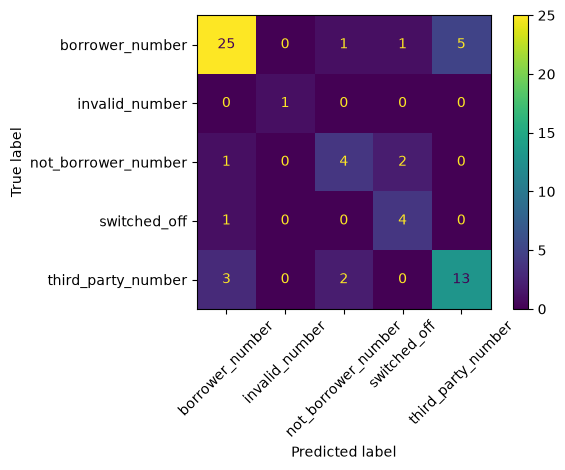

In [188]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_val_state,
    state_pred,
    xticks_rotation=45
)

plt.tight_layout()
plt.show()

In [189]:
verified["verified_status"].value_counts()

verified_status
borrower_number        127
third_party_number      74
not_borrower_number     27
switched_off            19
invalid_number           3
Name: count, dtype: int64

In [190]:
print(
    verified["verified_status"]
    .value_counts()
)

verified_status
borrower_number        127
third_party_number      74
not_borrower_number     27
switched_off            19
invalid_number           3
Name: count, dtype: int64


In [191]:
print("Accuracy:", round(state_accuracy, 4))
print("Macro F1:", round(state_macro_f1, 4))

print(
    classification_report(
        y_val_state,
        state_pred,
        zero_division=0
    )
)

Accuracy: 0.746
Macro F1: 0.7534
                     precision    recall  f1-score   support

    borrower_number       0.83      0.78      0.81        32
     invalid_number       1.00      1.00      1.00         1
not_borrower_number       0.57      0.57      0.57         7
       switched_off       0.57      0.80      0.67         5
 third_party_number       0.72      0.72      0.72        18

           accuracy                           0.75        63
          macro avg       0.74      0.77      0.75        63
       weighted avg       0.75      0.75      0.75        63



In [192]:
dial_state = dial.copy()

dial_state["attempt_ts"] = pd.to_datetime(
    dial_state["attempt_ts"]
)

dial_state["flag_rpc"] = dial_state["is_rpc"].astype(int)

dial_state["flag_answered"] = (
    dial_state["network_response"] == "answered"
).astype(int)

dial_state["flag_no_answer"] = (
    dial_state["network_response"] == "ring_no_answer"
).astype(int)

dial_state["flag_rejected"] = (
    dial_state["network_response"] == "busy_rejected"
).astype(int)

dial_state["flag_not_reachable"] = (
    dial_state["network_response"] == "not_reachable"
).astype(int)

dial_state["flag_switched_off"] = (
    dial_state["network_response"] == "switched_off"
).astype(int)

dial_state["flag_invalid_network"] = (
    dial_state["network_response"] == "number_does_not_exist"
).astype(int)

dial_state["flag_third_party"] = (
    dial_state["disposition"].isin(
        ["third_party_contact", "third_party_ptp"]
    )
).astype(int)

dial_state["flag_wrong_number"] = (
    dial_state["disposition"] == "wrong_number"
).astype(int)

dial_state["flag_invalid_disposition"] = (
    dial_state["disposition"] == "invalid_number"
).astype(int)

In [193]:
current_phone_history = (
    dial_state
    .groupby(
        ["account_id", "phone_id"]
    )
    .agg(

        hist_attempts=(
            "attempt_id",
            "count"
        ),

        hist_rpc_count=(
            "flag_rpc",
            "sum"
        ),

        hist_answered_count=(
            "flag_answered",
            "sum"
        ),

        hist_no_answer_count=(
            "flag_no_answer",
            "sum"
        ),

        hist_rejected_count=(
            "flag_rejected",
            "sum"
        ),

        hist_not_reachable_count=(
            "flag_not_reachable",
            "sum"
        ),

        hist_switched_off_count=(
            "flag_switched_off",
            "sum"
        ),

        hist_invalid_network_count=(
            "flag_invalid_network",
            "sum"
        ),

        hist_third_party_count=(
            "flag_third_party",
            "sum"
        ),

        hist_wrong_number_count=(
            "flag_wrong_number",
            "sum"
        ),

        hist_invalid_disposition_count=(
            "flag_invalid_disposition",
            "sum"
        ),

        last_attempt_ts=(
            "attempt_ts",
            "max"
        )
    )
    .reset_index()
)

In [194]:
current_phone_history.head()

,account_id,phone_id,hist_attempts,hist_rpc_count,hist_answered_count,hist_no_answer_count,hist_rejected_count,hist_not_reachable_count,hist_switched_off_count,hist_invalid_network_count,hist_third_party_count,hist_wrong_number_count,hist_invalid_disposition_count,last_attempt_ts
0,AC000001,PH000611,8,0,0,0,0,5,3,0,0,0,0,2026-04-18 12:23:40
1,AC000001,PH000612,7,0,3,3,1,0,0,0,2,1,0,2026-05-13 11:58:13
2,AC000002,PH000613,1,0,0,1,0,0,0,0,0,0,0,2026-04-02 10:55:33
3,AC000003,PH000615,5,1,1,4,0,0,0,0,0,0,0,2026-04-04 08:20:48
4,AC000004,PH000618,5,1,1,3,1,0,0,0,0,0,0,2026-04-08 09:43:18


In [195]:
contact_now = (
    phones[
        [
            "account_id",
            "phone_id",
            "source",
            "relation_recorded",
            "priority_slot"
        ]
    ]
    .drop_duplicates(
        subset=["account_id", "phone_id"]
    )
    .merge(
        current_phone_history,
        on=["account_id", "phone_id"],
        how="left"
    )
)

In [196]:
print("Total phone contacts:", len(contact_now))
print(contact_now.shape)

Total phone contacts: 5719
(5719, 17)


In [197]:
current_count_features = [
    "hist_attempts",
    "hist_rpc_count",
    "hist_answered_count",
    "hist_no_answer_count",
    "hist_rejected_count",
    "hist_not_reachable_count",
    "hist_switched_off_count",
    "hist_invalid_network_count",
    "hist_third_party_count",
    "hist_wrong_number_count",
    "hist_invalid_disposition_count"
]

contact_now[current_count_features] = (
    contact_now[current_count_features]
    .fillna(0)
)

In [198]:
denom = (
    contact_now["hist_attempts"]
    .replace(0, np.nan)
)

contact_now["hist_rpc_rate"] = (
    contact_now["hist_rpc_count"] / denom
).fillna(0)

contact_now["hist_answer_rate"] = (
    contact_now["hist_answered_count"] / denom
).fillna(0)

contact_now["hist_no_answer_rate"] = (
    contact_now["hist_no_answer_count"] / denom
).fillna(0)

contact_now["hist_rejected_rate"] = (
    contact_now["hist_rejected_count"] / denom
).fillna(0)

contact_now["hist_not_reachable_rate"] = (
    contact_now["hist_not_reachable_count"] / denom
).fillna(0)

contact_now["hist_switched_off_rate"] = (
    contact_now["hist_switched_off_count"] / denom
).fillna(0)

contact_now["hist_invalid_network_rate"] = (
    contact_now["hist_invalid_network_count"] / denom
).fillna(0)

contact_now["hist_third_party_rate"] = (
    contact_now["hist_third_party_count"] / denom
).fillna(0)

contact_now["hist_wrong_number_rate"] = (
    contact_now["hist_wrong_number_count"] / denom
).fillna(0)

In [200]:
reference_ts = (
    dial_state["attempt_ts"].max().normalize()
    + pd.Timedelta(days=1)
    + pd.Timedelta(hours=10)
)

print("Scoring date:", reference_ts)

Scoring date: 2026-06-30 10:00:00


In [201]:
contact_now["days_since_last_attempt"] = (
    reference_ts
    - pd.to_datetime(
        contact_now["last_attempt_ts"]
    )
).dt.total_seconds() / 86400

contact_now["days_since_last_attempt"] = (
    contact_now["days_since_last_attempt"]
    .fillna(-1)
)

In [202]:
X_contact_state = (
    contact_now[state_features]
    .copy()
)

In [203]:
for col in state_categorical_features:

    X_contact_state[col] = (
        X_contact_state[col]
        .fillna("missing")
        .astype(str)
    )
    

In [204]:
for col in state_numeric_features:

    X_contact_state[col] = pd.to_numeric(
        X_contact_state[col],
        errors="coerce"
    )

In [205]:
contact_now["predicted_state"] = (
    state_model
    .predict(X_contact_state)
    .flatten()
)

In [206]:
contact_now[
    [
        "account_id",
        "phone_id",
        "predicted_state"
    ]
].head(20)

,account_id,phone_id,predicted_state
0,AC000001,PH000611,not_borrower_number
1,AC000001,PH000612,not_borrower_number
2,AC000002,PH000613,borrower_number
3,AC000002,PH000581,third_party_number
4,AC000002,PH000614,third_party_number
5,AC000003,PH000615,borrower_number
6,AC000003,PH000616,not_borrower_number
7,AC000003,PH000617,third_party_number
8,AC000004,PH000618,borrower_number
9,AC000004,PH000619,not_borrower_number


In [207]:
state_probabilities = (
    state_model.predict_proba(
        X_contact_state
    )
)

state_classes = list(
    state_model.classes_
)

print(state_classes)

['borrower_number', 'invalid_number', 'not_borrower_number', 'switched_off', 'third_party_number']


In [208]:
state_prob_df = pd.DataFrame(
    state_probabilities,
    columns=[
        "p_" + str(c)
        for c in state_classes
    ]
)

contact_now = pd.concat(
    [
        contact_now.reset_index(drop=True),
        state_prob_df.reset_index(drop=True)
    ],
    axis=1
)

In [209]:
verified_latest = (
    verified
    .sort_values("verified_date")
    .drop_duplicates(
        subset=["account_id", "phone_id"],
        keep="last"
    )
    [
        [
            "account_id",
            "phone_id",
            "verified_status",
            "verified_date"
        ]
    ]
)

In [210]:
contact_now = contact_now.merge(
    verified_latest,
    on=["account_id", "phone_id"],
    how="left"
)

In [211]:
contact_now["verified_status_now"] = (
    contact_now["verified_status"]
    .where(
        contact_now["verified_date"]
        <= reference_ts
    )
)

In [212]:
conditions = [

    (
        contact_now["hist_invalid_network_count"] > 0
    )
    |
    (
        contact_now["hist_invalid_disposition_count"] > 0
    ),

    (
        contact_now["hist_wrong_number_count"] > 0
    ),

    (
        contact_now["hist_third_party_count"] > 0
    )
]

choices = [

    "invalid_number",

    "not_borrower_number",

    "third_party_number"
]

contact_now["hard_evidence_state"] = np.select(
    conditions,
    choices,
    default=None
)

In [213]:
contact_now["operational_state"] = (
    contact_now["verified_status_now"]
    .combine_first(
        contact_now["hard_evidence_state"]
    )
    .combine_first(
        contact_now["predicted_state"]
    )
)

In [214]:
contact_now[
    [
        "account_id",
        "phone_id",
        "verified_status_now",
        "hard_evidence_state",
        "predicted_state",
        "operational_state"
    ]
].head(30)

,account_id,phone_id,verified_status_now,hard_evidence_state,predicted_state,operational_state
0,AC000001,PH000611,NaN,NaN,not_borrower_number,not_borrower_number
1,AC000001,PH000612,NaN,not_borrower_number,not_borrower_number,not_borrower_number
2,AC000002,PH000613,NaN,NaN,borrower_number,borrower_number
3,AC000002,PH000581,NaN,NaN,third_party_number,third_party_number
4,AC000002,PH000614,NaN,NaN,third_party_number,third_party_number
5,AC000003,PH000615,NaN,NaN,borrower_number,borrower_number
6,AC000003,PH000616,NaN,NaN,not_borrower_number,not_borrower_number
7,AC000003,PH000617,NaN,NaN,third_party_number,third_party_number
8,AC000004,PH000618,NaN,NaN,borrower_number,borrower_number
9,AC000004,PH000619,NaN,NaN,not_borrower_number,not_borrower_number


In [215]:
contact_decision = contact_now.merge(
    phone_ranking[
        [
            "account_id",
            "phone_id",
            "rpc_probability"
        ]
    ],
    on=["account_id", "phone_id"],
    how="left"
)

In [216]:
print(
    "Contacts without RPC probability:",
    contact_decision[
        "rpc_probability"
    ].isna().sum()
)

Contacts without RPC probability: 1685


In [217]:
def get_probability_column(df, name):

    column = "p_" + name

    if column in df.columns:
        return df[column]

    return pd.Series(
        0.0,
        index=df.index
    )

In [218]:
contact_decision["unsafe_probability"] = (

    get_probability_column(
        contact_decision,
        "invalid_number"
    )

    +

    get_probability_column(
        contact_decision,
        "not_borrower_number"
    )

    +

    get_probability_column(
        contact_decision,
        "third_party_number"
    )
)

In [219]:
contact_decision["unsafe_probability"] = (
    contact_decision[
        "unsafe_probability"
    ]
    .clip(0, 1)
)

In [220]:
contact_decision["safe_probability"] = (
    1
    - contact_decision["unsafe_probability"]
)

In [221]:
contact_decision[
    "contact_priority_score"
] = (

    contact_decision[
        "rpc_probability"
    ]

    *

    contact_decision[
        "safe_probability"
    ]
)

In [222]:
unsafe_states = [
    "invalid_number",
    "not_borrower_number",
    "third_party_number"
]

contact_decision.loc[
    contact_decision[
        "operational_state"
    ].isin(unsafe_states),

    "contact_priority_score"

] = 0

In [223]:
contact_decision[
    "score_for_ranking"
] = (

    contact_decision[
        "contact_priority_score"
    ]
    .fillna(-1)
)

In [224]:
contact_decision[
    "final_phone_rank"
] = (

    contact_decision
    .groupby("account_id")[
        "score_for_ranking"
    ]

    .rank(
        method="first",
        ascending=False
    )
    .astype(int)
)

In [225]:
contact_decision = (
    contact_decision
    .sort_values(
        [
            "account_id",
            "final_phone_rank"
        ]
    )
)

In [226]:
contact_decision[
    [
        "account_id",
        "phone_id",
        "operational_state",
        "rpc_probability",
        "safe_probability",
        "contact_priority_score",
        "final_phone_rank"
    ]
].head(30)

,account_id,phone_id,operational_state,rpc_probability,safe_probability,contact_priority_score,final_phone_rank
0,AC000001,PH000611,not_borrower_number,0.010295,0.403736,0.000000,1
1,AC000001,PH000612,not_borrower_number,0.052531,0.269224,0.000000,2
2,AC000002,PH000613,borrower_number,0.229406,0.605681,0.138947,1
3,AC000002,PH000581,third_party_number,NaN,0.043271,0.000000,2
4,AC000002,PH000614,third_party_number,NaN,0.032544,0.000000,3
5,AC000003,PH000615,borrower_number,0.280563,0.828223,0.232369,1
6,AC000003,PH000616,not_borrower_number,NaN,0.221656,0.000000,2
7,AC000003,PH000617,third_party_number,NaN,0.032544,0.000000,3
8,AC000004,PH000618,borrower_number,0.202068,0.850410,0.171841,1
9,AC000004,PH000619,not_borrower_number,NaN,0.221656,0.000000,2


In [227]:
def assign_contact_action(row):

    state = row["operational_state"]

    score = row["contact_priority_score"]

    rank = row["final_phone_rank"]

    if state == "invalid_number":
        return "SUPPRESS_INVALID"

    if state == "third_party_number":
        return "SUPPRESS_BORROWER_CAMPAIGN"

    if state == "not_borrower_number":
        return "SUPPRESS_NOT_BORROWER"

    if state == "switched_off":
        return "RETRY_LATER_OR_SWITCH"

    if rank == 1 and score >= 0.15:
        return "CALL_FIRST"

    if score >= 0.08:
        return "BACKUP_CONTACT"

    return "DEPRIORITIZE"

In [228]:
contact_decision["recommended_action"] = (
    contact_decision.apply(
        assign_contact_action,
        axis=1
    )
)

In [229]:
contact_decision[
    [
        "account_id",
        "phone_id",
        "operational_state",
        "rpc_probability",
        "safe_probability",
        "contact_priority_score",
        "final_phone_rank",
        "recommended_action"
    ]
].head(40)

,account_id,phone_id,operational_state,rpc_probability,safe_probability,contact_priority_score,final_phone_rank,recommended_action
0,AC000001,PH000611,not_borrower_number,0.010295,0.403736,0.000000,1,SUPPRESS_NOT_BORROWER
1,AC000001,PH000612,not_borrower_number,0.052531,0.269224,0.000000,2,SUPPRESS_NOT_BORROWER
2,AC000002,PH000613,borrower_number,0.229406,0.605681,0.138947,1,BACKUP_CONTACT
3,AC000002,PH000581,third_party_number,NaN,0.043271,0.000000,2,SUPPRESS_BORROWER_CAMPAIGN
4,AC000002,PH000614,third_party_number,NaN,0.032544,0.000000,3,SUPPRESS_BORROWER_CAMPAIGN
5,AC000003,PH000615,borrower_number,0.280563,0.828223,0.232369,1,CALL_FIRST
6,AC000003,PH000616,not_borrower_number,NaN,0.221656,0.000000,2,SUPPRESS_NOT_BORROWER
7,AC000003,PH000617,third_party_number,NaN,0.032544,0.000000,3,SUPPRESS_BORROWER_CAMPAIGN
8,AC000004,PH000618,borrower_number,0.202068,0.850410,0.171841,1,CALL_FIRST
9,AC000004,PH000619,not_borrower_number,NaN,0.221656,0.000000,2,SUPPRESS_NOT_BORROWER


In [230]:
contact_decision["is_usable_contact"] = (
    ~contact_decision[
        "operational_state"
    ].isin(unsafe_states)
).astype(int)

In [231]:
account_contact_summary = (
    contact_decision
    .groupby("account_id")
    .agg(

        total_contacts=(
            "phone_id",
            "count"
        ),

        usable_contacts=(
            "is_usable_contact",
            "sum"
        ),

        best_contact_score=(
            "contact_priority_score",
            "max"
        ),

        best_rpc_probability=(
            "rpc_probability",
            "max"
        )
    )
    .reset_index()
)

In [232]:
account_contact_summary[
    "skip_trace_candidate"
] = (

    account_contact_summary[
        "usable_contacts"
    ] == 0

).astype(int)

In [233]:
account_contact_summary[
    "skip_trace_candidate"
].value_counts()

skip_trace_candidate
0    1856
1     544
Name: count, dtype: int64

In [234]:
contact_decision.to_csv(
    "../data/contact_decision_table.csv",
    index=False
)

account_contact_summary.to_csv(
    "../data/account_contact_summary.csv",
    index=False
)

print("Contact decision tables saved.")

Contact decision tables saved.


In [235]:
print(
    "Missing RPC:",
    contact_decision["rpc_probability"]
    .isna()
    .sum()
)

Missing RPC: 1685


In [236]:
print(
    contact_decision[
        "recommended_action"
    ].value_counts()
)

recommended_action
SUPPRESS_BORROWER_CAMPAIGN    1806
SUPPRESS_NOT_BORROWER         1285
CALL_FIRST                    1052
DEPRIORITIZE                   560
BACKUP_CONTACT                 557
RETRY_LATER_OR_SWITCH          308
SUPPRESS_INVALID               151
Name: count, dtype: int64


In [237]:
print(
    account_contact_summary[
        "skip_trace_candidate"
    ].value_counts()
)

skip_trace_candidate
0    1856
1     544
Name: count, dtype: int64


In [238]:
skip = pd.read_csv("../data/skip_trace.csv")
payments = pd.read_csv("../data/payments.csv")

skip["trace_date"] = pd.to_datetime(skip["trace_date"])
payments["payment_ts"] = pd.to_datetime(payments["payment_ts"])

print("Skip traces:", skip.shape)
print("Payments:", payments.shape)

display(skip.head())

Skip traces: (766, 7)
Payments: (2162, 5)


,trace_id,account_id,trace_date,trigger_rule,result,new_contact_point_id,cost_inr
0,ST00001,AC000285,2026-04-13,15_consecutive_failed_contacts,new_phone_found,PH005811,87
1,ST00002,AC000276,2026-04-15,15_consecutive_failed_contacts,no_new_info,NaN,91
2,ST00003,AC001982,2026-04-18,15_consecutive_failed_contacts,no_new_info,NaN,108
3,ST00004,AC002103,2026-04-18,15_consecutive_failed_contacts,new_phone_found,PH005812,109
4,ST00005,AC002236,2026-04-19,15_consecutive_failed_contacts,no_new_info,NaN,132


In [239]:
print(skip["result"].value_counts(dropna=False))

print("\nTrigger rules:")
print(skip["trigger_rule"].value_counts(dropna=False))

print("\nCost:")
print(skip["cost_inr"].describe())

result
no_new_info          591
new_phone_found      148
new_address_found     27
Name: count, dtype: int64

Trigger rules:
trigger_rule
15_consecutive_failed_contacts    766
Name: count, dtype: int64

Cost:
count    766.000000
mean     103.981723
std       26.648468
min       60.000000
25%       81.000000
50%      102.000000
75%      127.000000
max      150.000000
Name: cost_inr, dtype: float64


In [240]:
skip["trace_success"] = (
    skip["result"] == "new_phone_found"
).astype(int)

print(skip["trace_success"].value_counts())

print(
    "Success rate:",
    round(skip["trace_success"].mean(), 4)
)

trace_success
0    618
1    148
Name: count, dtype: int64
Success rate: 0.1932


In [241]:
trace_history = skip[
    [
        "trace_id",
        "account_id",
        "trace_date",
        "trace_success"
    ]
].merge(
    dial,
    on="account_id",
    how="left"
)

trace_history = trace_history[
    trace_history["attempt_ts"]
    < trace_history["trace_date"]
].copy()

print(trace_history.shape)

(14903, 20)


In [242]:
trace_history["flag_rpc"] = (
    trace_history["is_rpc"].astype(int)
)

trace_history["flag_no_answer"] = (
    trace_history["network_response"]
    == "ring_no_answer"
).astype(int)

trace_history["flag_rejected"] = (
    trace_history["network_response"]
    == "busy_rejected"
).astype(int)

trace_history["flag_not_reachable"] = (
    trace_history["network_response"]
    == "not_reachable"
).astype(int)

trace_history["flag_switched_off"] = (
    trace_history["network_response"]
    == "switched_off"
).astype(int)

trace_history["flag_invalid"] = (
    trace_history["network_response"]
    == "number_does_not_exist"
).astype(int)

trace_history["flag_third_party"] = (
    trace_history["disposition"].isin(
        [
            "third_party_contact",
            "third_party_ptp"
        ]
    )
).astype(int)

trace_history["flag_wrong_number"] = (
    trace_history["disposition"]
    == "wrong_number"
).astype(int)

In [243]:
trace_features = (
    trace_history
    .groupby("trace_id")
    .agg(

        pre_attempts=(
            "attempt_id",
            "count"
        ),

        pre_unique_phones=(
            "phone_id",
            "nunique"
        ),

        pre_rpc_count=(
            "flag_rpc",
            "sum"
        ),

        pre_no_answer_count=(
            "flag_no_answer",
            "sum"
        ),

        pre_rejected_count=(
            "flag_rejected",
            "sum"
        ),

        pre_not_reachable_count=(
            "flag_not_reachable",
            "sum"
        ),

        pre_switched_off_count=(
            "flag_switched_off",
            "sum"
        ),

        pre_invalid_count=(
            "flag_invalid",
            "sum"
        ),

        pre_third_party_count=(
            "flag_third_party",
            "sum"
        ),

        pre_wrong_number_count=(
            "flag_wrong_number",
            "sum"
        ),

        pre_last_attempt_ts=(
            "attempt_ts",
            "max"
        )
    )
    .reset_index()
)

In [244]:
skip_ml = skip.merge(
    trace_features,
    on="trace_id",
    how="left",
    validate="one_to_one"
)

print(skip_ml.shape)

(766, 19)


In [245]:
skip_count_features = [
    "pre_attempts",
    "pre_unique_phones",
    "pre_rpc_count",
    "pre_no_answer_count",
    "pre_rejected_count",
    "pre_not_reachable_count",
    "pre_switched_off_count",
    "pre_invalid_count",
    "pre_third_party_count",
    "pre_wrong_number_count"
]

skip_ml[skip_count_features] = (
    skip_ml[skip_count_features]
    .fillna(0)
)

In [246]:
denom = (
    skip_ml["pre_attempts"]
    .replace(0, np.nan)
)

skip_ml["pre_rpc_rate"] = (
    skip_ml["pre_rpc_count"] / denom
).fillna(0)

skip_ml["pre_no_answer_rate"] = (
    skip_ml["pre_no_answer_count"] / denom
).fillna(0)

skip_ml["pre_rejected_rate"] = (
    skip_ml["pre_rejected_count"] / denom
).fillna(0)

skip_ml["pre_not_reachable_rate"] = (
    skip_ml["pre_not_reachable_count"] / denom
).fillna(0)

skip_ml["pre_switched_off_rate"] = (
    skip_ml["pre_switched_off_count"] / denom
).fillna(0)

skip_ml["pre_invalid_rate"] = (
    skip_ml["pre_invalid_count"] / denom
).fillna(0)

skip_ml["pre_third_party_rate"] = (
    skip_ml["pre_third_party_count"] / denom
).fillna(0)

skip_ml["pre_wrong_number_rate"] = (
    skip_ml["pre_wrong_number_count"] / denom
).fillna(0)

In [247]:
skip_ml["days_since_last_attempt"] = (
    skip_ml["trace_date"]
    - skip_ml["pre_last_attempt_ts"]
).dt.total_seconds() / 86400

skip_ml["days_since_last_attempt"] = (
    skip_ml["days_since_last_attempt"]
    .fillna(-1)
)

In [248]:
accounts_skip = accounts.drop(
    columns=["dialling_arm"],
    errors="ignore"
)

skip_ml = skip_ml.merge(
    accounts_skip,
    on="account_id",
    how="left",
    validate="many_to_one"
)

In [249]:
skip_ml = skip_ml.merge(
    splits,
    on="account_id",
    how="left",
    validate="many_to_one"
)

print(skip_ml["split"].value_counts(dropna=False))

split
train         523
validation    134
test          109
Name: count, dtype: int64


In [250]:
skip_numeric_features = [

    "pre_attempts",
    "pre_unique_phones",

    "pre_rpc_count",
    "pre_no_answer_count",
    "pre_rejected_count",
    "pre_not_reachable_count",
    "pre_switched_off_count",
    "pre_invalid_count",
    "pre_third_party_count",
    "pre_wrong_number_count",

    "pre_rpc_rate",
    "pre_no_answer_rate",
    "pre_rejected_rate",
    "pre_not_reachable_rate",
    "pre_switched_off_rate",
    "pre_invalid_rate",
    "pre_third_party_rate",
    "pre_wrong_number_rate",

    "days_since_last_attempt",

    "dpd_start",
    "emi_amount",
    "overdue_start",
    "outstanding",
    "salary_credit_day",
    "other_active_loans",
    "ability_to_pay_estimate",
    "prev_ptp_count",
    "prev_ptp_broken",

    "cost_inr"
]

In [251]:
skip_categorical_features = [
    "lender_id",
    "portfolio",
    "income_type",
    "town_id",
    "preferred_language",
    "bucket_start",
    "bureau_score_band",
    "paid_other_lenders_30d",
    "last_bounce_reason"
]

In [252]:
skip_features = (
    skip_numeric_features
    + skip_categorical_features
)

skip_target = "trace_success"

In [253]:
missing_skip_features = [
    col
    for col in skip_features
    if col not in skip_ml.columns
]

print(
    "Missing skip features:",
    missing_skip_features
)

Missing skip features: []


In [254]:
skip_train = (
    skip_ml[
        skip_ml["split"] == "train"
    ]
    .copy()
)

skip_val = (
    skip_ml[
        skip_ml["split"] == "validation"
    ]
    .copy()
)

skip_test = (
    skip_ml[
        skip_ml["split"] == "test"
    ]
    .copy()
)

print("Train:", skip_train.shape)
print("Validation:", skip_val.shape)
print("Test:", skip_test.shape)

print()
print(
    "Train success rate:",
    round(skip_train["trace_success"].mean(), 4)
)

print(
    "Validation success rate:",
    round(skip_val["trace_success"].mean(), 4)
)

Train: (523, 47)
Validation: (134, 47)
Test: (109, 47)

Train success rate: 0.1816
Validation success rate: 0.194


In [255]:
X_skip_train = (
    skip_train[skip_features]
    .copy()
)

y_skip_train = (
    skip_train[skip_target]
    .copy()
)

X_skip_val = (
    skip_val[skip_features]
    .copy()
)

y_skip_val = (
    skip_val[skip_target]
    .copy()
)

In [256]:
for col in skip_categorical_features:

    X_skip_train[col] = (
        X_skip_train[col]
        .fillna("missing")
        .astype(str)
    )

    X_skip_val[col] = (
        X_skip_val[col]
        .fillna("missing")
        .astype(str)
    )

In [257]:
for col in skip_numeric_features:

    X_skip_train[col] = pd.to_numeric(
        X_skip_train[col],
        errors="coerce"
    )

    X_skip_val[col] = pd.to_numeric(
        X_skip_val[col],
        errors="coerce"
    )

In [258]:
skip_model = CatBoostClassifier(

    iterations=800,

    depth=5,

    learning_rate=0.04,

    loss_function="Logloss",

    eval_metric="AUC",

    auto_class_weights="Balanced",

    l2_leaf_reg=5,

    random_seed=42,

    verbose=100,

    allow_writing_files=False
)

In [259]:
skip_model.fit(

    X_skip_train,
    y_skip_train,

    cat_features=skip_categorical_features,

    eval_set=(
        X_skip_val,
        y_skip_val
    ),

    early_stopping_rounds=100,

    use_best_model=True
)

0:	test: 0.7083333	best: 0.7083333 (0)	total: 18ms	remaining: 14.3s
100:	test: 0.7820513	best: 0.7927350 (81)	total: 6.96s	remaining: 48.2s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.7927350427
bestIteration = 81

Shrink model to first 82 iterations.


CatBoostClassifier(allow_writing_files=False, auto_class_weights='Balanced', depth=5, eval_metric='AUC', iterations=800, l2_leaf_reg=5, learning_rate=0.04, loss_function='Logloss', random_seed=42, verbose=100)

In [260]:
skip_val_prob = (
    skip_model.predict_proba(
        X_skip_val
    )[:, 1]
)

In [261]:
skip_roc_auc = roc_auc_score(
    y_skip_val,
    skip_val_prob
)

skip_pr_auc = average_precision_score(
    y_skip_val,
    skip_val_prob
)

skip_brier = brier_score_loss(
    y_skip_val,
    skip_val_prob
)

print("SKIP-TRACE MODEL")

print(
    "ROC-AUC:",
    round(skip_roc_auc, 4)
)

print(
    "PR-AUC:",
    round(skip_pr_auc, 4)
)

print(
    "Brier:",
    round(skip_brier, 4)
)

print(
    "Success prevalence:",
    round(y_skip_val.mean(), 4)
)

SKIP-TRACE MODEL
ROC-AUC: 0.7927
PR-AUC: 0.5346
Brier: 0.1647
Success prevalence: 0.194


In [262]:
skip_importance = pd.DataFrame({

    "feature":
        skip_features,

    "importance":
        skip_model.get_feature_importance()
})

skip_importance = (
    skip_importance
    .sort_values(
        "importance",
        ascending=False
    )
)

skip_importance.head(15)

,feature,importance
12,pre_rejected_rate,33.417175
4,pre_rejected_count,9.536742
14,pre_switched_off_rate,7.848981
5,pre_not_reachable_count,3.771439
13,pre_not_reachable_rate,3.251652
16,pre_third_party_rate,3.145673
33,preferred_language,2.889287
20,emi_amount,2.651421
11,pre_no_answer_rate,2.426239
3,pre_no_answer_count,2.117572


In [263]:
skip_importance.head(15)

,feature,importance
12,pre_rejected_rate,33.417175
4,pre_rejected_count,9.536742
14,pre_switched_off_rate,7.848981
5,pre_not_reachable_count,3.771439
13,pre_not_reachable_rate,3.251652
16,pre_third_party_rate,3.145673
33,preferred_language,2.889287
20,emi_amount,2.651421
11,pre_no_answer_rate,2.426239
3,pre_no_answer_count,2.117572


In [264]:
print(payments.shape)
display(payments.head())

print(payments["amount"].describe())

(2162, 5)


,payment_id,account_id,payment_ts,amount,channel
0,PY0000001,AC000457,2026-04-01 19:57:52,3800.0,branch_cash
1,PY0000002,AC000067,2026-04-01 13:50:03,38700.0,nach_represent
2,PY0000003,AC000106,2026-04-01 15:54:08,2350.0,neft
3,PY0000004,AC000468,2026-04-01 19:21:32,3450.0,nach_represent
4,PY0000005,AC000471,2026-04-01 20:25:12,31600.0,bbps


count      2162.000000
mean      12659.088807
std       25686.080043
min          50.000000
25%        2100.000000
50%        4800.000000
75%       12487.500000
max      438000.000000
Name: amount, dtype: float64


In [265]:
trace_times = (
    skip[
        ["trace_id", "account_id", "trace_date"]
    ]
    .sort_values(["trace_date"])
    .copy()
)

payment_assign = (
    payments[
        ["payment_id", "account_id", "payment_ts", "amount"]
    ]
    .sort_values(["payment_ts"])
    .copy()
)

In [266]:
payment_assign = pd.merge_asof(
    payment_assign,
    trace_times,
    left_on="payment_ts",
    right_on="trace_date",
    by="account_id",
    direction="backward"
)

In [267]:
payment_assign["days_after_trace"] = (
    payment_assign["payment_ts"]
    - payment_assign["trace_date"]
).dt.total_seconds() / 86400

In [268]:
payment_assign_30d = payment_assign[
    (payment_assign["days_after_trace"] >= 0)
    &
    (payment_assign["days_after_trace"] <= 30)
].copy()

print(payment_assign_30d.shape)

(134, 7)


In [269]:
trace_recovery = (
    payment_assign_30d
    .groupby("trace_id")
    .agg(
        recovery_30d=("amount", "sum"),
        payments_30d=("payment_id", "count")
    )
    .reset_index()
)

In [270]:
skip_ml = skip_ml.merge(
    trace_recovery,
    on="trace_id",
    how="left"
)

skip_ml["recovery_30d"] = (
    skip_ml["recovery_30d"]
    .fillna(0)
)

skip_ml["payments_30d"] = (
    skip_ml["payments_30d"]
    .fillna(0)
)

In [271]:
skip_ml[
    [
        "trace_id",
        "trace_success",
        "recovery_30d",
        "cost_inr"
    ]
].head(20)

,trace_id,trace_success,recovery_30d,cost_inr
0,ST00001,1,0.0,87
1,ST00002,0,1900.0,91
2,ST00003,0,13200.0,108
3,ST00004,1,0.0,109
4,ST00005,0,0.0,132
5,ST00006,0,0.0,72
6,ST00007,0,3250.0,135
7,ST00008,0,7000.0,87
8,ST00009,0,0.0,91
9,ST00010,0,0.0,142


In [272]:
skip_ml["recovered_30d"] = (
    skip_ml["recovery_30d"] > 0
).astype(int)

print(
    skip_ml["recovered_30d"]
    .value_counts()
)

print(
    "30-day recovery rate:",
    round(
        skip_ml["recovered_30d"].mean(),
        4
    )
)

recovered_30d
0    636
1    130
Name: count, dtype: int64
30-day recovery rate: 0.1697


In [273]:
skip_ml["recoverable_exposure"] = (
    skip_ml["overdue_start"]
    .where(
        skip_ml["overdue_start"] > 0,
        skip_ml["outstanding"]
    )
)

In [274]:
skip_ml["recoverable_exposure"] = (
    pd.to_numeric(
        skip_ml["recoverable_exposure"],
        errors="coerce"
    )
    .fillna(0)
    .clip(lower=0)
)

In [275]:
skip_ml["recovery_rate_30d"] = np.where(
    skip_ml["recoverable_exposure"] > 0,

    skip_ml["recovery_30d"]
    /
    skip_ml["recoverable_exposure"],

    0
)

In [276]:
skip_ml["recovery_rate_30d"] = (
    skip_ml["recovery_rate_30d"]
    .clip(0, 1)
)

In [277]:
skip_ml["recovery_rate_30d"].describe()

count    766.000000
mean       0.112895
std        0.282142
min        0.000000
25%        0.000000
50%        0.000000
75%        0.000000
max        1.000000
Name: recovery_rate_30d, dtype: float64

In [278]:
recovery_train = skip_ml[
    skip_ml["split"] == "train"
].copy()

successful_recovery_train = recovery_train[
    recovery_train["trace_success"] == 1
].copy()

print(
    "Successful training traces:",
    len(successful_recovery_train)
)

Successful training traces: 95


In [279]:
global_success_recovery_rate = (
    successful_recovery_train[
        "recovery_rate_30d"
    ].mean()
)

print(
    "Average 30-day recovery rate after successful trace:",
    round(global_success_recovery_rate, 4)
)

Average 30-day recovery rate after successful trace: 0.1407


In [280]:
bucket_recovery = (
    successful_recovery_train
    .groupby("bucket_start")
    ["recovery_rate_30d"]
    .agg(["count", "mean"])
    .reset_index()
)

bucket_recovery

,bucket_start,count,mean
0,1-30,32,0.127365
1,31-60,19,0.207634
2,61-90,14,0.071429
3,90+,14,0.113900
4,X,16,0.171957


In [281]:
alpha = 20

bucket_recovery["smoothed_recovery_rate"] = (
    (
        bucket_recovery["count"]
        * bucket_recovery["mean"]
    )
    +
    (
        alpha
        * global_success_recovery_rate
    )
) / (
    bucket_recovery["count"]
    + alpha
)

bucket_recovery

,bucket_start,count,mean,smoothed_recovery_rate
0,1-30,32,0.127365,0.132494
1,31-60,19,0.207634,0.173310
2,61-90,14,0.071429,0.112177
3,90+,14,0.113900,0.129665
4,X,16,0.171957,0.154593


In [282]:
current_skip_history = (
    dial_state
    .groupby("account_id")
    .agg(

        pre_attempts=(
            "attempt_id",
            "count"
        ),

        pre_unique_phones=(
            "phone_id",
            "nunique"
        ),

        pre_rpc_count=(
            "flag_rpc",
            "sum"
        ),

        pre_no_answer_count=(
            "flag_no_answer",
            "sum"
        ),

        pre_rejected_count=(
            "flag_rejected",
            "sum"
        ),

        pre_not_reachable_count=(
            "flag_not_reachable",
            "sum"
        ),

        pre_switched_off_count=(
            "flag_switched_off",
            "sum"
        ),

        pre_invalid_count=(
            "flag_invalid_network",
            "sum"
        ),

        pre_third_party_count=(
            "flag_third_party",
            "sum"
        ),

        pre_wrong_number_count=(
            "flag_wrong_number",
            "sum"
        ),

        pre_last_attempt_ts=(
            "attempt_ts",
            "max"
        )
    )
    .reset_index()
)

In [283]:
denom = (
    current_skip_history["pre_attempts"]
    .replace(0, np.nan)
)

current_skip_history["pre_rpc_rate"] = (
    current_skip_history["pre_rpc_count"] / denom
).fillna(0)

current_skip_history["pre_no_answer_rate"] = (
    current_skip_history["pre_no_answer_count"] / denom
).fillna(0)

current_skip_history["pre_rejected_rate"] = (
    current_skip_history["pre_rejected_count"] / denom
).fillna(0)

current_skip_history["pre_not_reachable_rate"] = (
    current_skip_history["pre_not_reachable_count"] / denom
).fillna(0)

current_skip_history["pre_switched_off_rate"] = (
    current_skip_history["pre_switched_off_count"] / denom
).fillna(0)

current_skip_history["pre_invalid_rate"] = (
    current_skip_history["pre_invalid_count"] / denom
).fillna(0)

current_skip_history["pre_third_party_rate"] = (
    current_skip_history["pre_third_party_count"] / denom
).fillna(0)

current_skip_history["pre_wrong_number_rate"] = (
    current_skip_history["pre_wrong_number_count"] / denom
).fillna(0)

In [284]:
current_skip_history[
    "days_since_last_attempt"
] = (
    reference_ts
    - current_skip_history[
        "pre_last_attempt_ts"
    ]
).dt.total_seconds() / 86400

In [285]:
current_skip_candidates = (
    account_contact_summary[
        account_contact_summary[
            "skip_trace_candidate"
        ] == 1
    ][
        ["account_id"]
    ]
    .copy()
)

print(
    "Current skip-trace candidates:",
    len(current_skip_candidates)
)

Current skip-trace candidates: 544


In [286]:
current_skip_candidates = (
    current_skip_candidates
    .merge(
        current_skip_history,
        on="account_id",
        how="left"
    )
    .merge(
        accounts_skip,
        on="account_id",
        how="left",
        validate="one_to_one"
    )
)

In [287]:
estimated_trace_cost = (
    skip_train["cost_inr"].median()
)

print(
    "Estimated trace cost:",
    estimated_trace_cost
)

current_skip_candidates["cost_inr"] = (
    estimated_trace_cost
)

Estimated trace cost: 103.0


In [288]:
missing_current_skip = [
    col
    for col in skip_features
    if col not in current_skip_candidates.columns
]

print(
    "Missing current skip features:",
    missing_current_skip
)

Missing current skip features: []


In [289]:
X_current_skip = (
    current_skip_candidates[
        skip_features
    ]
    .copy()
)

In [290]:
for col in skip_categorical_features:

    X_current_skip[col] = (
        X_current_skip[col]
        .fillna("missing")
        .astype(str)
    )

In [291]:
for col in skip_numeric_features:

    X_current_skip[col] = pd.to_numeric(
        X_current_skip[col],
        errors="coerce"
    )

In [292]:
current_skip_candidates[
    "p_trace_success"
] = (
    skip_model.predict_proba(
        X_current_skip
    )[:, 1]
)

In [293]:
current_skip_candidates[
    "p_trace_success"
].describe()

count    544.000000
mean       0.446853
std        0.206555
min        0.049097
25%        0.304342
50%        0.488786
75%        0.617094
max        0.805948
Name: p_trace_success, dtype: float64

In [294]:
current_skip_candidates = (
    current_skip_candidates
    .merge(
        bucket_recovery[
            [
                "bucket_start",
                "smoothed_recovery_rate"
            ]
        ],
        on="bucket_start",
        how="left"
    )
)

In [295]:
current_skip_candidates[
    "smoothed_recovery_rate"
] = (
    current_skip_candidates[
        "smoothed_recovery_rate"
    ]
    .fillna(
        global_success_recovery_rate
    )
)

In [296]:
current_skip_candidates[
    "recoverable_exposure"
] = (
    current_skip_candidates[
        "overdue_start"
    ]
    .where(
        current_skip_candidates[
            "overdue_start"
        ] > 0,

        current_skip_candidates[
            "outstanding"
        ]
    )
)

In [297]:
current_skip_candidates[
    "recoverable_exposure"
] = (
    pd.to_numeric(
        current_skip_candidates[
            "recoverable_exposure"
        ],
        errors="coerce"
    )
    .fillna(0)
    .clip(lower=0)
)

In [298]:
current_skip_candidates[
    "expected_recovery_if_success"
] = (

    current_skip_candidates[
        "recoverable_exposure"
    ]

    *

    current_skip_candidates[
        "smoothed_recovery_rate"
    ]
)

In [299]:
current_skip_candidates[
    "expected_gross_recovery"
] = (

    current_skip_candidates[
        "p_trace_success"
    ]

    *

    current_skip_candidates[
        "expected_recovery_if_success"
    ]
)

In [300]:
current_skip_candidates[
    "net_expected_value"
] = (

    current_skip_candidates[
        "expected_gross_recovery"
    ]

    -

    current_skip_candidates[
        "cost_inr"
    ]
)

In [301]:
current_skip_candidates[
    "expected_roi"
] = np.where(

    current_skip_candidates[
        "cost_inr"
    ] > 0,

    current_skip_candidates[
        "net_expected_value"
    ]
    /
    current_skip_candidates[
        "cost_inr"
    ],

    np.nan
)

In [302]:
current_skip_candidates[
    "skip_trace_rank"
] = (
    current_skip_candidates[
        "net_expected_value"
    ]
    .rank(
        method="first",
        ascending=False
    )
    .astype(int)
)

In [303]:
current_skip_candidates = (
    current_skip_candidates
    .sort_values(
        "skip_trace_rank"
    )
)

In [304]:
def assign_skip_action(row):

    if row["net_expected_value"] <= 0:
        return "DO_NOT_TRACE"

    if row["p_trace_success"] < 0.20:
        return "LOW_PRIORITY_TRACE"

    return "TRACE_NOW"

In [305]:
current_skip_candidates[
    "skip_trace_action"
] = (
    current_skip_candidates
    .apply(
        assign_skip_action,
        axis=1
    )
)

In [306]:
display(
    current_skip_candidates[
        [
            "account_id",
            "p_trace_success",
            "recoverable_exposure",
            "smoothed_recovery_rate",
            "expected_gross_recovery",
            "cost_inr",
            "net_expected_value",
            "expected_roi",
            "skip_trace_rank",
            "skip_trace_action"
        ]
    ].head(30)
)

,account_id,p_trace_success,recoverable_exposure,smoothed_recovery_rate,expected_gross_recovery,cost_inr,net_expected_value,expected_roi,skip_trace_rank,skip_trace_action
124,AC000497,0.697903,214200.0,0.129665,19383.780867,103.0,19280.780867,187.192047,1,TRACE_NOW
499,AC002182,0.631359,217800.0,0.129665,17830.286272,103.0,17727.286272,172.109575,2,TRACE_NOW
332,AC001406,0.542423,199800.0,0.129665,14052.631770,103.0,13949.631770,135.433318,3,TRACE_NOW
421,AC001830,0.554926,160000.0,0.129665,11512.762004,103.0,11409.762004,110.774388,4,TRACE_NOW
27,AC000112,0.579206,126800.0,0.129665,9523.054165,103.0,9420.054165,91.456837,5,TRACE_NOW
497,AC002174,0.361199,191400.0,0.129665,8964.219754,103.0,8861.219754,86.031260,6,TRACE_NOW
276,AC001139,0.737178,102450.0,0.112177,8472.069890,103.0,8369.069890,81.253106,7,TRACE_NOW
543,AC002400,0.644586,96300.0,0.129665,8048.800143,103.0,7945.800143,77.143691,8,TRACE_NOW
225,AC000945,0.504672,121800.0,0.129665,7970.409338,103.0,7867.409338,76.382615,9,TRACE_NOW
7,AC000041,0.593768,74100.0,0.173310,7625.315943,103.0,7522.315943,73.032194,10,TRACE_NOW


In [307]:
print(
    current_skip_candidates[
        "skip_trace_action"
    ].value_counts()
)

skip_trace_action
TRACE_NOW             428
LOW_PRIORITY_TRACE     58
DO_NOT_TRACE           58
Name: count, dtype: int64


In [308]:
print(
    "Total candidates:",
    len(current_skip_candidates)
)

print(
    "Positive-EV traces:",
    (
        current_skip_candidates[
            "net_expected_value"
        ] > 0
    ).sum()
)

Total candidates: 544
Positive-EV traces: 486


In [309]:
print(
    "Projected net EV across selected traces:",
    round(
        current_skip_candidates.loc[
            current_skip_candidates[
                "net_expected_value"
            ] > 0,
            "net_expected_value"
        ].sum(),
        2
    )
)

Projected net EV across selected traces: 567694.7


In [310]:
current_skip_candidates.to_csv(
    "../data/skip_trace_prioritization.csv",
    index=False
)

print(
    "Skip-trace prioritisation saved."
)

Skip-trace prioritisation saved.


In [311]:
print(
    current_skip_candidates[
        "skip_trace_action"
    ].value_counts()
)

skip_trace_action
TRACE_NOW             428
LOW_PRIORITY_TRACE     58
DO_NOT_TRACE           58
Name: count, dtype: int64


In [312]:
current_skip_candidates[
    "p_trace_success"
].describe()

count    544.000000
mean       0.446853
std        0.206555
min        0.049097
25%        0.304342
50%        0.488786
75%        0.617094
max        0.805948
Name: p_trace_success, dtype: float64

In [313]:
current_skip_candidates[
    "net_expected_value"
].describe()

count      544.000000
mean      1038.796016
std       1909.558342
min        -86.371657
25%        108.454777
50%        385.350057
75%       1170.803912
max      19280.780867
Name: net_expected_value, dtype: float64

In [320]:
best_contact = (
    contact_decision[
        contact_decision["final_phone_rank"] == 1
    ]
    .copy()
)

best_contact = best_contact[
    [
        "account_id",
        "phone_id",
        "operational_state",
        "safe_probability",
        "recommended_action"
    ]
]

best_contact = best_contact.rename(
    columns={
        "phone_id": "best_phone_id",
        "operational_state": "best_phone_state",
        "safe_probability": "best_safe_probability",
        "recommended_action": "best_phone_action"
    }
)

best_contact.head()

,account_id,best_phone_id,best_phone_state,best_safe_probability,best_phone_action
0,AC000001,PH000611,not_borrower_number,0.403736,SUPPRESS_NOT_BORROWER
2,AC000002,PH000613,borrower_number,0.605681,BACKUP_CONTACT
5,AC000003,PH000615,borrower_number,0.828223,CALL_FIRST
8,AC000004,PH000618,borrower_number,0.850410,CALL_FIRST
10,AC000005,PH000620,third_party_number,0.847219,SUPPRESS_BORROWER_CAMPAIGN


In [322]:
final_decision = (
    account_contact_summary
    .merge(
        best_contact,
        on="account_id",
        how="left",
        validate="one_to_one"
    )
)

print(final_decision.shape)

print(final_decision.columns.tolist())

(2400, 10)
['account_id', 'total_contacts', 'usable_contacts', 'best_contact_score', 'best_rpc_probability', 'skip_trace_candidate', 'best_phone_id', 'best_phone_state', 'best_safe_probability', 'best_phone_action']


In [323]:
print(
    final_decision[
        [
            "account_id",
            "best_phone_id",
            "best_phone_state",
            "best_rpc_probability",
            "best_contact_score",
            "best_safe_probability"
        ]
    ].head()
)

  account_id best_phone_id     best_phone_state  best_rpc_probability  \
0   AC000001      PH000611  not_borrower_number              0.052531   
1   AC000002      PH000613      borrower_number              0.229406   
2   AC000003      PH000615      borrower_number              0.280563   
3   AC000004      PH000618      borrower_number              0.202068   
4   AC000005      PH000620   third_party_number              0.212503   

   best_contact_score  best_safe_probability  
0            0.000000               0.403736  
1            0.138947               0.605681  
2            0.232369               0.828223  
3            0.171841               0.850410  
4            0.000000               0.847219  


In [324]:
skip_output = (
    current_skip_candidates[
        [
            "account_id",
            "p_trace_success",
            "expected_gross_recovery",
            "cost_inr",
            "net_expected_value",
            "expected_roi",
            "skip_trace_rank",
            "skip_trace_action"
        ]
    ]
    .copy()
)

final_decision = final_decision.merge(
    skip_output,
    on="account_id",
    how="left",
    validate="one_to_one"
)

print(final_decision.shape)

(2400, 17)


In [325]:
def final_action_logic(row):

    if row["skip_trace_candidate"] == 0:

        if row["best_phone_state"] == "switched_off":
            return "RETRY_OR_SWITCH_TIME"

        if row["best_contact_score"] >= 0.15:
            return "CALL_BEST_CONTACT"

        if row["best_contact_score"] >= 0.08:
            return "TRY_BEST_CONTACT"

        return "DEPRIORITIZE_CONTACT"

    else:

        if row["skip_trace_action"] == "TRACE_NOW":
            return "SKIP_TRACE_NOW"

        if row["skip_trace_action"] == "LOW_PRIORITY_TRACE":
            return "SKIP_TRACE_LOW_PRIORITY"

        if row["skip_trace_action"] == "DO_NOT_TRACE":
            return "DO_NOT_SKIP_TRACE"

        return "REVIEW_MANUALLY"

In [326]:
final_decision["final_action"] = (
    final_decision.apply(
        final_action_logic,
        axis=1
    )
)

In [327]:
final_decision["final_action"].value_counts()

final_action
CALL_BEST_CONTACT          1052
SKIP_TRACE_NOW              428
TRY_BEST_CONTACT            416
DEPRIORITIZE_CONTACT        225
RETRY_OR_SWITCH_TIME        163
SKIP_TRACE_LOW_PRIORITY      58
DO_NOT_SKIP_TRACE            58
Name: count, dtype: int64

In [328]:
print(
    final_decision["final_action"]
    .value_counts()
)

final_action
CALL_BEST_CONTACT          1052
SKIP_TRACE_NOW              428
TRY_BEST_CONTACT            416
DEPRIORITIZE_CONTACT        225
RETRY_OR_SWITCH_TIME        163
SKIP_TRACE_LOW_PRIORITY      58
DO_NOT_SKIP_TRACE            58
Name: count, dtype: int64


In [329]:
def generate_reason(row):

    action = row["final_action"]

    if action == "CALL_BEST_CONTACT":

        return (
            f"Best existing phone has RPC probability "
            f"{row['best_rpc_probability']:.2f} and contact score "
            f"{row['best_contact_score']:.2f}."
        )

    if action == "TRY_BEST_CONTACT":

        return (
            f"No high-confidence contact, but best phone remains usable "
            f"with contact score {row['best_contact_score']:.2f}."
        )

    if action == "RETRY_OR_SWITCH_TIME":

        return (
            "Best available number appears switched off; "
            "retry later or change calling time."
        )

    if action == "SKIP_TRACE_NOW":

        return (
            f"No viable known contact. Skip-trace success probability "
            f"{row['p_trace_success']:.2f}, estimated net value "
            f"₹{row['net_expected_value']:.0f}."
        )

    if action == "SKIP_TRACE_LOW_PRIORITY":

        return (
            f"No viable known contact, but predicted skip-trace "
            f"success is only {row['p_trace_success']:.2f}."
        )

    if action == "DO_NOT_SKIP_TRACE":

        return (
            f"Skip trace has non-positive estimated value "
            f"₹{row['net_expected_value']:.0f}."
        )

    return "Low-priority account requiring manual review."

In [330]:
final_decision["decision_reason"] = (
    final_decision.apply(
        generate_reason,
        axis=1
    )
)

In [331]:
display(
    final_decision[
        [
            "account_id",
            "best_phone_id",
            "best_phone_state",
            "best_rpc_probability",
            "best_contact_score",
            "p_trace_success",
            "net_expected_value",
            "final_action",
            "decision_reason"
        ]
    ].head(30)
)

,account_id,best_phone_id,best_phone_state,best_rpc_probability,best_contact_score,p_trace_success,net_expected_value,final_action,decision_reason
0,AC000001,PH000611,not_borrower_number,0.052531,0.000000,0.463691,2510.786793,SKIP_TRACE_NOW,No viable known contact. Skip-trace success pr...
1,AC000002,PH000613,borrower_number,0.229406,0.138947,NaN,NaN,TRY_BEST_CONTACT,"No high-confidence contact, but best phone rem..."
2,AC000003,PH000615,borrower_number,0.280563,0.232369,NaN,NaN,CALL_BEST_CONTACT,Best existing phone has RPC probability 0.28 a...
3,AC000004,PH000618,borrower_number,0.202068,0.171841,NaN,NaN,CALL_BEST_CONTACT,Best existing phone has RPC probability 0.20 a...
4,AC000005,PH000620,third_party_number,0.212503,0.000000,0.381681,96.753665,SKIP_TRACE_NOW,No viable known contact. Skip-trace success pr...
5,AC000006,PH000622,borrower_number,0.192037,0.163266,NaN,NaN,CALL_BEST_CONTACT,Best existing phone has RPC probability 0.19 a...
6,AC000007,PH000625,borrower_number,0.129772,0.092430,NaN,NaN,TRY_BEST_CONTACT,"No high-confidence contact, but best phone rem..."
7,AC000008,PH000627,borrower_number,0.263699,0.226589,NaN,NaN,CALL_BEST_CONTACT,Best existing phone has RPC probability 0.26 a...
8,AC000009,PH000631,borrower_number,0.188493,0.139153,NaN,NaN,TRY_BEST_CONTACT,"No high-confidence contact, but best phone rem..."
9,AC000010,PH000632,borrower_number,0.221965,0.185375,NaN,NaN,CALL_BEST_CONTACT,Best existing phone has RPC probability 0.22 a...


In [332]:
account_exposure = accounts[
    [
        "account_id",
        "outstanding",
        "overdue_start"
    ]
].copy()

final_decision = final_decision.merge(
    account_exposure,
    on="account_id",
    how="left",
    validate="one_to_one"
)

In [333]:
final_decision["recoverable_exposure"] = (
    final_decision["overdue_start"]
    .where(
        final_decision["overdue_start"] > 0,
        final_decision["outstanding"]
    )
)

final_decision["recoverable_exposure"] = (
    pd.to_numeric(
        final_decision["recoverable_exposure"],
        errors="coerce"
    )
    .fillna(0)
    .clip(lower=0)
)

In [334]:
final_decision["account_priority_score"] = np.where(

    final_decision["skip_trace_candidate"] == 0,

    final_decision["best_contact_score"].fillna(0)
    *
    final_decision["recoverable_exposure"],

    final_decision["net_expected_value"]
    .fillna(0)
    .clip(lower=0)
)

In [335]:
final_decision["overall_priority_rank"] = (
    final_decision[
        "account_priority_score"
    ]
    .rank(
        method="first",
        ascending=False
    )
    .astype(int)
)

In [336]:
final_decision = (
    final_decision
    .sort_values(
        "overall_priority_rank"
    )
    .reset_index(drop=True)
)

In [337]:
display(
    final_decision[
        [
            "overall_priority_rank",
            "account_id",
            "recoverable_exposure",
            "best_phone_id",
            "best_rpc_probability",
            "best_phone_state",
            "p_trace_success",
            "net_expected_value",
            "final_action"
        ]
    ].head(25)
)

,overall_priority_rank,account_id,recoverable_exposure,best_phone_id,best_rpc_probability,best_phone_state,p_trace_success,net_expected_value,final_action
0,1,AC002224,438000.0,PH005432,0.253442,borrower_number,NaN,NaN,CALL_BEST_CONTACT
1,2,AC001466,387600.0,PH003810,0.253279,borrower_number,NaN,NaN,CALL_BEST_CONTACT
2,3,AC001462,288000.0,PH003802,0.247267,borrower_number,NaN,NaN,CALL_BEST_CONTACT
3,4,AC000173,223800.0,PH000988,0.258263,borrower_number,NaN,NaN,CALL_BEST_CONTACT
4,5,AC000140,266800.0,PH000919,0.224037,borrower_number,NaN,NaN,CALL_BEST_CONTACT
5,6,AC001266,395000.0,PH003374,0.145307,borrower_number,NaN,NaN,TRY_BEST_CONTACT
6,7,AC002293,201000.0,PH005584,0.219642,borrower_number,NaN,NaN,CALL_BEST_CONTACT
7,8,AC001457,175600.0,PH003788,0.263013,borrower_number,NaN,NaN,CALL_BEST_CONTACT
8,9,AC002144,300400.0,PH005255,0.147441,borrower_number,NaN,NaN,TRY_BEST_CONTACT
9,10,AC000336,460200.0,PH001321,0.094678,borrower_number,NaN,NaN,DEPRIORITIZE_CONTACT


In [338]:
final_decision["compliance_flag"] = np.where(

    final_decision["best_phone_state"].isin(
        [
            "third_party_number",
            "not_borrower_number",
            "invalid_number"
        ]
    ),

    "DO_NOT_CONTACT",

    "OK"
)

In [339]:
final_decision[
    "compliance_flag"
].value_counts()

compliance_flag
OK                1758
DO_NOT_CONTACT     642
Name: count, dtype: int64

In [340]:
unsafe_best = (
    final_decision["compliance_flag"]
    == "DO_NOT_CONTACT"
)

In [341]:
final_decision.loc[
    unsafe_best &
    (final_decision["skip_trace_candidate"] == 0),
    "final_action"
] = "REVIEW_CONTACT_SET"


In [342]:
decision_summary = (
    final_decision[
        "final_action"
    ]
    .value_counts()
    .rename_axis("action")
    .reset_index(name="accounts")
)

decision_summary

,action,accounts
0,CALL_BEST_CONTACT,1052
1,SKIP_TRACE_NOW,428
2,TRY_BEST_CONTACT,416
3,RETRY_OR_SWITCH_TIME,163
4,DEPRIORITIZE_CONTACT,127
5,REVIEW_CONTACT_SET,98
6,SKIP_TRACE_LOW_PRIORITY,58
7,DO_NOT_SKIP_TRACE,58


In [343]:
decision_summary["percentage"] = (
    100
    *
    decision_summary["accounts"]
    /
    len(final_decision)
)

decision_summary["percentage"] = (
    decision_summary["percentage"]
    .round(2)
)

decision_summary

,action,accounts,percentage
0,CALL_BEST_CONTACT,1052,43.83
1,SKIP_TRACE_NOW,428,17.83
2,TRY_BEST_CONTACT,416,17.33
3,RETRY_OR_SWITCH_TIME,163,6.79
4,DEPRIORITIZE_CONTACT,127,5.29
5,REVIEW_CONTACT_SET,98,4.08
6,SKIP_TRACE_LOW_PRIORITY,58,2.42
7,DO_NOT_SKIP_TRACE,58,2.42


In [344]:
suppressed_contacts = (
    contact_decision[
        "operational_state"
    ].isin(
        [
            "third_party_number",
            "not_borrower_number",
            "invalid_number"
        ]
    )
    .sum()
)

print(
    "Unsafe contacts suppressed:",
    suppressed_contacts
)

Unsafe contacts suppressed: 3242


In [345]:
print(
    "Accounts with viable known contact:",
    (
        final_decision[
            "skip_trace_candidate"
        ] == 0
    ).sum()
)

print(
    "Accounts requiring skip-trace evaluation:",
    (
        final_decision[
            "skip_trace_candidate"
        ] == 1
    ).sum()
)

Accounts with viable known contact: 1856
Accounts requiring skip-trace evaluation: 544


In [346]:
print(
    "TRACE NOW:",
    (
        final_decision[
            "final_action"
        ] == "SKIP_TRACE_NOW"
    ).sum()
)

print(
    "LOW PRIORITY TRACE:",
    (
        final_decision[
            "final_action"
        ] == "SKIP_TRACE_LOW_PRIORITY"
    ).sum()
)

print(
    "DO NOT TRACE:",
    (
        final_decision[
            "final_action"
        ] == "DO_NOT_SKIP_TRACE"
    ).sum()
)

TRACE NOW: 428
LOW PRIORITY TRACE: 58
DO NOT TRACE: 58


In [347]:
selected_trace_value = (
    final_decision.loc[
        final_decision["final_action"]
        == "SKIP_TRACE_NOW",

        "net_expected_value"
    ]
    .sum()
)

print(
    "Model-estimated net recovery value:",
    round(selected_trace_value, 2)
)

Model-estimated net recovery value: 544538.11


In [348]:
final_decision.to_csv(
    "../data/final_decision_engine.csv",
    index=False
)

decision_summary.to_csv(
    "../data/decision_summary.csv",
    index=False
)

print("Final decision engine saved successfully.")

Final decision engine saved successfully.


In [349]:
import os

os.makedirs(
    "../models",
    exist_ok=True
)

In [350]:
import joblib

joblib.dump(
    logistic_model,
    "../models/logistic_rpc_model.pkl"
)

print("Logistic model saved.")

Logistic model saved.


In [351]:
cat_model.save_model(
    "../models/catboost_rpc_model.cbm"
)

print("RPC CatBoost model saved.")

RPC CatBoost model saved.


In [352]:
state_model.save_model(
    "../models/contact_state_model.cbm"
)

print("Contact-state model saved.")

Contact-state model saved.


In [353]:
skip_model.save_model(
    "../models/skip_trace_model.cbm"
)

print("Skip-trace model saved.")

Skip-trace model saved.


In [354]:
print(
    os.listdir("../models")
)

['catboost_rpc_model.cbm', 'contact_state_model.cbm', 'logistic_rpc_model.pkl', 'skip_trace_model.cbm']


In [355]:
decision_summary

,action,accounts,percentage
0,CALL_BEST_CONTACT,1052,43.83
1,SKIP_TRACE_NOW,428,17.83
2,TRY_BEST_CONTACT,416,17.33
3,RETRY_OR_SWITCH_TIME,163,6.79
4,DEPRIORITIZE_CONTACT,127,5.29
5,REVIEW_CONTACT_SET,98,4.08
6,SKIP_TRACE_LOW_PRIORITY,58,2.42
7,DO_NOT_SKIP_TRACE,58,2.42


In [356]:
print(
    "Unsafe contacts suppressed:",
    suppressed_contacts
)

Unsafe contacts suppressed: 3242


In [357]:
final_decision[
    [
        "overall_priority_rank",
        "account_id",
        "best_phone_id",
        "final_action",
        "account_priority_score",
        "decision_reason"
    ]
].head(10)

,overall_priority_rank,account_id,best_phone_id,final_action,account_priority_score,decision_reason
0,1,AC002224,PH005432,CALL_BEST_CONTACT,97450.700606,Best existing phone has RPC probability 0.25 a...
1,2,AC001466,PH003810,CALL_BEST_CONTACT,84525.086706,Best existing phone has RPC probability 0.25 a...
2,3,AC001462,PH003802,CALL_BEST_CONTACT,61335.939849,Best existing phone has RPC probability 0.25 a...
3,4,AC000173,PH000988,CALL_BEST_CONTACT,52517.089071,Best existing phone has RPC probability 0.26 a...
4,5,AC000140,PH000919,CALL_BEST_CONTACT,51998.652142,Best existing phone has RPC probability 0.22 a...
5,6,AC001266,PH003374,TRY_BEST_CONTACT,50875.804396,"No high-confidence contact, but best phone rem..."
6,7,AC002293,PH005584,CALL_BEST_CONTACT,40167.844184,Best existing phone has RPC probability 0.22 a...
7,8,AC001457,PH003788,CALL_BEST_CONTACT,38799.346805,Best existing phone has RPC probability 0.26 a...
8,9,AC002144,PH005255,TRY_BEST_CONTACT,38439.721242,"No high-confidence contact, but best phone rem..."
9,10,AC000336,PH001321,DEPRIORITIZE_CONTACT,36722.332658,Low-priority account requiring manual review.


In [358]:
def generate_final_reason(row):

    action = row["final_action"]

    if action == "CALL_BEST_CONTACT":
        return (
            f"Best existing phone has RPC probability "
            f"{row['best_rpc_probability']:.2f} and contact score "
            f"{row['best_contact_score']:.2f}."
        )

    if action == "TRY_BEST_CONTACT":
        return (
            f"Best available phone remains usable with contact score "
            f"{row['best_contact_score']:.2f}."
        )

    if action == "RETRY_OR_SWITCH_TIME":
        return (
            "Best available contact appears switched off; "
            "retry later or change calling time."
        )

    if action == "SKIP_TRACE_NOW":
        return (
            f"No viable known contact. Skip-trace success probability "
            f"{row['p_trace_success']:.2f}; estimated net value "
            f"₹{row['net_expected_value']:.0f}."
        )

    if action == "SKIP_TRACE_LOW_PRIORITY":
        return (
            f"No viable known contact, but skip-trace success probability "
            f"is only {row['p_trace_success']:.2f}."
        )

    if action == "DO_NOT_SKIP_TRACE":
        return (
            f"Estimated skip-trace net value is "
            f"₹{row['net_expected_value']:.0f}, so tracing is not economical."
        )

    if action == "REVIEW_CONTACT_SET":
        return (
            "Highest-ranked known contact is restricted by the safety layer; "
            "review available contacts before any borrower communication."
        )

    if action == "DEPRIORITIZE_CONTACT":
        return (
            "Known contacts have low current contact priority."
        )

    return "Manual review recommended."

In [359]:
final_decision["decision_reason"] = (
    final_decision.apply(
        generate_final_reason,
        axis=1
    )
)

In [360]:
final_decision.to_csv(
    "../data/final_decision_engine.csv",
    index=False
)

In [363]:
print(
    contact_decision["rpc_probability"]
    .isna()
    .sum()
)

1685


In [364]:
contact_decision.to_csv(
    "../data/contact_decision_table.csv",
    index=False
)

print("Updated contact table saved.")

Updated contact table saved.
